# Three-year colorectal cancer-specific mortality classification (SEER 2018–2020)

Analysis code for the manuscript *Explainable and Uncertainty-Aware Machine Learning for 3-Year Colorectal Cancer-Specific Mortality Risk Classification: A SEER-Based Temporal Validation Study*.

Patients diagnosed in 2018–2019 form the development cohort, and patients diagnosed in 2020 form the temporal test cohort. Table and figure numbers follow the manuscript. Tables labelled "S" are in Online Resource 1. The SEER data file is not distributed with the code.

**Contents**

1. Setup
2. Data loading
3. Cohort and outcome
4. Predictors and preprocessing
5. Development/test split and data checks
6. Descriptive statistics
7. Evaluation functions
8. Model development and selection
9. Calibration and test-set performance
10. Staging baselines and decision curve analysis
11. Stage-wise, subgroup and predictor-set analyses
12. Sensitivity analyses
13. Prediction sets
14. Explainability
15. Secondary analyses
16. Figures
17. Reproducibility check

## 1. Setup

Libraries, random seed and the analysis constants used throughout: cross-validation folds, tuning trials, bootstrap replicates, the 36-month horizon and the target coverage for prediction sets.

In [1]:
import os, re, random, warnings, platform
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna, shap
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
                             brier_score_loss)
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.utils import concordance_index
from lifelines.statistics import proportional_hazard_test
from sksurv.metrics import brier_score as sk_brier, cumulative_dynamic_auc as sk_auc
from sksurv.util import Surv

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
# Set SEER_DATA_FILE to override the default location. The SEER source data
# are not distributed with this repository.
_default_data_name = "NEW_CRC_2018-2020.txt"
if os.environ.get("SEER_DATA_FILE"):
    DATA_FILE = os.environ["SEER_DATA_FILE"]
else:
    _data_candidates = [
        os.path.join("data", _default_data_name),
        os.path.join("..", "data", _default_data_name),
    ]
    DATA_FILE = next((p for p in _data_candidates if os.path.isfile(p)), _data_candidates[0])

# Save figures in the repository-level results/ folder whether Jupyter is
# launched from the repository root or from notebooks/.
_out_candidates = ["results", os.path.join("..", "results")]
OUT = next((p for p in _out_candidates if os.path.isdir(p)), "results")
N_FOLDS = 5
N_TRIALS = 50                            # Optuna trials per tree model
N_BOOT = 1000                            # bootstrap replicates
N_SHAP = 2000                            # patients used for SHAP
MIN_SUBGROUP = 100                       # smallest subgroup that is analysed
TARGET_COVERAGE = 0.90                   # conformal target
TRAIN_YEARS, TEST_YEAR, HORIZON = [2018, 2019], 2020, 36
THR_GRID = np.round(np.arange(0.05, 0.9501, 0.005), 3)   # F1 threshold search
DCA_GRID = np.linspace(0.05, 0.60, 56)                    # decision-curve thresholds
UNK = "Unknown/Not documented"

random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
os.makedirs(OUT, exist_ok=True)

for p in ["numpy", "pandas", "scikit-learn", "catboost", "xgboost", "lightgbm", "optuna", "shap", "lifelines", "scikit-survival"]:
    print(p, md.version(p))
print("python", platform.python_version())

numpy 2.2.6
pandas 2.3.3
scikit-learn 1.7.2
catboost 1.2.10
xgboost 3.2.0
lightgbm 4.7.0
optuna 5.0.0
shap 0.49.1
lifelines 0.30.0
scikit-survival 0.25.0
python 3.10.21


## 2. Data loading

SEER*Stat case listing (2018–2020). All fields are read as text and converted explicitly in later sections.

In [2]:
# SEER column names used in the analysis
YEAR, AGE, SEX = "Year of diagnosis", "Age recode with <1 year olds and 90+", "Sex"
RACE, HISP = "Race recode (W, B, AI, API)", "Origin recode NHIA (Hispanic, Non-Hisp)"
PID, SEQ = "Patient ID", "Sequence number"
SITE_RECODE, SITE_LABEL, HISTO = "Site recode ICD-O-3/WHO 2008", "Primary Site - labeled", "Histologic Type ICD-O-3"
GRADE, DIAG = "Derived Summary Grade 2018 (2018+)", "Diagnostic Confirmation"
SUMSTAGE, STAGEGRP = "Combined Summary Stage with Expanded Regional Codes (2004+)", "Derived EOD 2018 Stage Group Recode (2018+)"
T_COL, N_COL, M_COL = "Derived EOD 2018 T Recode (2018+)", "Derived EOD 2018 N Recode (2018+)", "Derived EOD 2018 M Recode (2018+)"
TSIZE, EOD_T, EOD_N, EOD_M = "Tumor Size Summary (2016+)", "EOD Primary Tumor Recode (2018+)", "EOD Regional Nodes Recode (2018+)", "EOD Mets Recode (2018+)"
NODES_EXAM, NODES_POS = "Regional nodes examined (1988+)", "Regional nodes positive (1988+)"
TUMOR_DEP, CEA, PNI = "Tumor Deposits Recode (2010+)", "CEA Pretreatment Interpretation Recode (2010+)", "Perineural Invasion Recode (2010+)"
SURV, VITAL, CSS_DEATH = "Survival months", "Vital status recode (study cutoff used)", "SEER cause-specific death classification"

raw = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False, low_memory=False)
raw.columns = [c.strip() for c in raw.columns]
print(raw.shape[0], "rows,", raw.shape[1], "columns;", raw[PID].nunique(), "unique patients")

104092 rows, 39 columns; 101555 unique patients


## 3. Cohort and outcome

**Output:** patient attrition (Table S1A), the share of patients without a defined outcome by year (Table S1B), and the counts shown in Fig. 1.

The cohort is restricted to first primary cancers of the colon and rectum (C18–C20, appendix excluded). The outcome is defined at 36 months:

- **Survivor (1):** followed for at least 36 months.
- **Cancer-specific death (0):** death from colorectal cancer before 36 months.
- **Undefined:** censored before 36 months or death from another cause. These patients are excluded from the analytic cohort and handled separately in the censoring analyses (Section 15).

In the models and evaluation below, cancer-specific death within 36 months is the positive class.

In [3]:
def overlap_ids(df):
    # patients who appear in both a training year and the test year
    year = pd.to_numeric(df[YEAR].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")
    return set(df.loc[year.isin(TRAIN_YEARS), PID]) & set(df.loc[year.eq(TEST_YEAR), PID])

attrition = [{"Step": "Raw SEER export", "Before N": len(raw), "Excluded": 0, "Remaining N": len(raw)}]
def add_step(name, before, after, note=""):
    attrition.append({"Step": name, "Before N": before, "Excluded": before - after, "Remaining N": after, "Note": note})

d = raw.copy()
overlap_raw = overlap_ids(d)

# colon and rectum only (C18-C20), appendix (C18.1) excluded
before = len(d)
keep = d[SITE_LABEL].str.contains(r"C18\.|C19\.|C20\.", na=False) & ~d[SITE_LABEL].str.contains(r"C18\.1", na=False)
d = d[keep].reset_index(drop=True)
add_step("Strict C18-C20 sites, appendix (C18.1) excluded", before, len(d))
overlap_site = overlap_ids(d)

# first primary only
before = len(d)
d = d[d[SEQ].str.strip().isin(["One primary only", "1st of 2 or more primaries"])].reset_index(drop=True)
add_step("First primary only (Sequence number)", before, len(d))
overlap_first = overlap_ids(d)

# patients present in both periods are dropped (none remain after the first-primary filter)
before = len(d)
d = d[~d[PID].isin(overlap_first)].reset_index(drop=True)
add_step("Drop residual train/test patient overlap", before, len(d))

# survival time and cause of death
d["year_numeric"] = pd.to_numeric(d[YEAR].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")
d["survival_months"] = pd.to_numeric(d[SURV].str.strip(), errors="coerce")
d["death_event_crc"] = d[CSS_DEATH].str.strip().eq("Dead (attributable to this cancer dx)").astype(int)
unknown_cod = d[VITAL].str.strip().eq("Dead") & d[CSS_DEATH].str.strip().eq("Dead (missing/unknown COD)")

before = len(d)
lab = d[~(d["survival_months"].isna() | unknown_cod)].reset_index(drop=True)
add_step("Missing survival months or unknown cause of death", before, len(lab))

# 36-month outcome: survivor = 1, CRC death before 36 months = 0, everything else undefined
crc_early = lab["death_event_crc"].eq(1) & lab["survival_months"].lt(HORIZON)
followed_36 = lab["survival_months"].ge(HORIZON)
lab["target"] = np.nan
lab.loc[crc_early, "target"] = 0
lab.loc[followed_36, "target"] = 1
lab["target_best_case"] = np.where(crc_early, 0, 1)    # undefined -> survivor
lab["target_worst_case"] = np.where(followed_36, 1, 0)  # undefined -> death

before = len(lab)
n_defined = int(lab["target"].notna().sum())
add_step("Undefined 3-year target (censored before 36 months or non-CRC death)", before, n_defined)

table_s1a = pd.DataFrame(attrition)
overlap_rows = pd.DataFrame([
    {"Step": "Overlap check: raw extract", "Note": f"{len(overlap_raw)} patients in both train years and 2020"},
    {"Step": "Overlap check: after site filter", "Note": f"{len(overlap_site)} patients"},
    {"Step": "Overlap check: after first-primary filter", "Note": f"{len(overlap_first)} patients"}])
display(pd.concat([table_s1a, overlap_rows], ignore_index=True).fillna(""))

# Table S1B: share without a defined outcome, by year
rows = []
for year, g in lab.groupby("year_numeric"):
    rows.append({"Year of diagnosis": int(year), "N (before target step)": len(g), "N with defined target": int(g["target"].notna().sum()),
                 "Excluded %": round(100 * (1 - g["target"].notna().mean()), 2)})
table_s1b = pd.DataFrame(rows)
display(table_s1b)

,Step,Before N,Excluded,Remaining N,Note
0,Raw SEER export,104092.0,0.0,104092.0,
1,"Strict C18-C20 sites, appendix (C18.1) excluded",104092.0,0.0,104092.0,
2,First primary only (Sequence number),104092.0,20473.0,83619.0,
3,Drop residual train/test patient overlap,83619.0,0.0,83619.0,
4,Missing survival months or unknown cause of death,83619.0,1924.0,81695.0,
5,Undefined 3-year target (censored before 36 mo...,81695.0,8932.0,72763.0,
6,Overlap check: raw extract,,,,210 patients in both train years and 2020
7,Overlap check: after site filter,,,,210 patients
8,Overlap check: after first-primary filter,,,,0 patients


,Year of diagnosis,N (before target step),N with defined target,Excluded %
0,2018,27740,25188,9.20
1,2019,28429,25387,10.70
2,2020,25526,22188,13.08


## 4. Predictors and preprocessing

Predictors are demographic, anatomic, pathologic and staging variables recorded in SEER at diagnosis. Cleaning steps:

- Missing-value codes are mapped to one "unknown" category.
- Special codes (for example, tumour size and node counts) are separated from measured values, so that codes are not treated as numbers.
- EOD codes are treated as nominal categories.

The full set has 26 predictors. A second, pretreatment-approximate set of 21 predictors omits the five nodal and tumour-deposit variables. It is used in Table S6B.

In [4]:
MISSING_TOKENS = {"", " ", "Unknown", "unknown", "Blank(s)", "nan", "NaN", "None", "NA", "Not documented", "Not documented/assessed",
    "Not documented; Interpretation not assessed or unknown if assessed",
    "Not documented/assessed; No mention in path report; Pathologist cant determine",
    "Not documented/assessed; Indeterminate; No mention in path report; No resection", "Unable to calculate"}

def clean_text(s, extra=()):
    # trim text and replace missing-value codes by one "unknown" label
    s = s.astype(str).str.strip()
    return s.where(~(s.isin(MISSING_TOKENS) | s.isin(extra)), UNK)

def to_number(s):
    return pd.to_numeric(s.astype(str).str.strip(), errors="coerce")

def age_midpoint(v):
    s = str(v).strip()
    if not s or s in MISSING_TOKENS: return np.nan
    if "90+" in s: return 90.0
    if "<1" in s: return 0.0
    n = re.findall(r"\d+", s)
    return (float(n[0]) + float(n[1])) / 2 if len(n) >= 2 else (float(n[0]) if n else np.nan)

def site_name(v):
    s = str(v).strip()
    return s.split("-", 1)[1].strip() if "-" in s else (UNK if s in MISSING_TOKENS else s)

def stage_group(v):
    s = str(v).strip()
    if s in MISSING_TOKENS or s in {"88", "99", ""}: return "Unknown/unstaged"
    m = re.match(r"^([0-4])([ABC])?$", s)
    return "Stage " + dict(zip("01234", ["0", "I", "II", "III", "IV"]))[m.group(1)] if m else s

def summary_stage(v):
    s = str(v).strip().lower()
    for key, name in [("localized", "Localized"), ("regional", "Regional"), ("distant", "Distant")]:
        if key in s: return name
    if "unknown" in s or "unstaged" in s or s in {"", "blank(s)"}: return "Unknown/unstaged"
    return str(v).strip()

GRADE_MAP = {"Site-specific grade system category (1)": "Grade 1", "Site-specific grade system category (2)": "Grade 2",
             "Site-specific grade system category (3)": "Grade 3", "Site-specific grade system category (4)": "Grade 4",
             "Well differentiated": "Grade 1", "Moderately differentiated": "Grade 2", "Poorly differentiated": "Grade 3",
             "Undifferentiated and anaplastic": "Grade 4"}
def grade_group(s, min_n=50):
    g = clean_text(s).map(GRADE_MAP).fillna("Unknown/indeterminate grade")
    rare = g.value_counts()[lambda v: v < min_n].index      # grades with <50 patients are pooled (uses the combined cohort)
    return g.replace({c: "Unknown/indeterminate grade" for c in rare})

# all engineered columns are added to the full labelled cohort
feat_full = lab.copy()
feat_full["age_numeric"] = feat_full[AGE].apply(age_midpoint)
feat_full["sex_clean"] = clean_text(feat_full[SEX])
feat_full["race_clean"] = clean_text(feat_full[RACE])
feat_full["hispanic_origin_clean"] = clean_text(feat_full[HISP])
feat_full["site_group"] = feat_full[SITE_LABEL].apply(site_name)
feat_full["site_recode_clean"] = clean_text(feat_full[SITE_RECODE])
feat_full["histology_clean"] = clean_text(feat_full[HISTO])
feat_full["grade_clean"] = grade_group(feat_full[GRADE])
feat_full["diagnostic_confirmation_clean"] = clean_text(feat_full[DIAG])
feat_full["summary_stage_clean"] = feat_full[SUMSTAGE].apply(summary_stage)
feat_full["stage_group_clean"] = feat_full[STAGEGRP].apply(stage_group)

# 88 and 99 mean "not applicable/unknown" in T, N and M only
for source, new in [(T_COL, "t_stage_clean"), (N_COL, "n_stage_clean"), (M_COL, "m_stage_clean")]:
    feat_full[new] = clean_text(feat_full[source], extra=("88", "99"))

# EOD codes are nominal categories (999 and 99 mean unknown)
feat_full["eod_primary_tumor_clean"] = clean_text(feat_full[EOD_T], extra=("999",))
feat_full["eod_regional_nodes_clean"] = clean_text(feat_full[EOD_N], extra=("999",))
feat_full["eod_mets_clean"] = clean_text(feat_full[EOD_M], extra=("99",))

# tumour size: millimetres plus a category for the special codes
size = to_number(feat_full[TSIZE])
feat_full["tumor_size_special"] = np.select(
    [size.isna().to_numpy() | size.eq(999).to_numpy(), size.eq(0).to_numpy(), size.eq(990).to_numpy(), size.eq(998).to_numpy(), size.between(1, 500).to_numpy()],
    ["Unknown/NA", "No mass/indeterminate", "Microscopic focus", "Polyposis/other", "Measured"], default="Implausible")
feat_full["tumor_size_mm"] = np.where(size.between(1, 500), size, np.where(size.eq(990), 1.0, np.nan))

# lymph nodes: real counts are 0-90, other values are special codes
pos, exa = to_number(feat_full[NODES_POS]), to_number(feat_full[NODES_EXAM])
feat_full["regional_nodes_positive"] = pos.where(pos.between(0, 90))
feat_full["regional_nodes_examined"] = exa.where(exa.between(0, 90))
feat_full["nodal_assessment"] = np.select(
    [(pos.isna() | exa.isna()).to_numpy(), (pos.eq(98) | exa.eq(0)).to_numpy(), (pos.eq(99) | exa.eq(99)).to_numpy(),
     (pos.isin([95, 97]) | exa.isin([95, 96, 97, 98])).to_numpy()],
    ["Unknown", "No nodes examined", "Unknown", "Examined, count unspecified"], default="Examined, count known")
n_exam, n_pos = feat_full["regional_nodes_examined"], feat_full["regional_nodes_positive"]
feat_full["node_ratio"] = (n_pos / n_exam).where((n_exam >= 1) & (n_pos <= n_exam))

feat_full["cea_clean"] = clean_text(feat_full[CEA])
feat_full["pni_clean"] = clean_text(feat_full[PNI])
feat_full["tumor_deposits_clean"] = clean_text(feat_full[TUMOR_DEP])

# analytic cohort = patients with a defined 36-month outcome
feat = feat_full[feat_full["target"].notna()].reset_index(drop=True)
feat["target"] = feat["target"].astype(int)

PRIMARY_FEATURES = ["age_numeric", "sex_clean", "race_clean", "hispanic_origin_clean", "site_group", "site_recode_clean", "histology_clean",
    "grade_clean", "diagnostic_confirmation_clean", "summary_stage_clean", "stage_group_clean", "t_stage_clean", "n_stage_clean", "m_stage_clean",
    "tumor_size_mm", "tumor_size_special", "eod_primary_tumor_clean", "eod_regional_nodes_clean", "eod_mets_clean",
    "regional_nodes_examined", "regional_nodes_positive", "node_ratio", "nodal_assessment", "cea_clean", "pni_clean", "tumor_deposits_clean"]
NODE_FEATURES = ["regional_nodes_examined", "regional_nodes_positive", "node_ratio", "nodal_assessment", "tumor_deposits_clean"]
PRETREATMENT_FEATURES = [c for c in PRIMARY_FEATURES if c not in NODE_FEATURES]    # 21 variables
print(len(PRIMARY_FEATURES), "predictors in the full set;", len(PRETREATMENT_FEATURES), "in the pretreatment-approximate set")

26 predictors in the full set; 21 in the pretreatment-approximate set


## 5. Development/test split and data checks

The split is by year of diagnosis, which gives a temporal rather than a random test set. The assertions confirm that predictors contain no outcome-derived variables, that no patient appears in both cohorts, and that coded values are within valid ranges.

In [5]:
train_rows = feat["year_numeric"].isin(TRAIN_YEARS).to_numpy()
test_rows = feat["year_numeric"].eq(TEST_YEAR).to_numpy()
X_train, X_test = feat.loc[train_rows, PRIMARY_FEATURES].reset_index(drop=True), feat.loc[test_rows, PRIMARY_FEATURES].reset_index(drop=True)
y_train, y_test = feat.loc[train_rows, "target"].to_numpy(int), feat.loc[test_rows, "target"].to_numpy(int)    # 1 = survivor, 0 = CRC death
train_meta, test_meta = feat.loc[train_rows].reset_index(drop=True), feat.loc[test_rows].reset_index(drop=True)
yd_train, yd_test = 1 - y_train, 1 - y_test      # death within 36 months = positive class
NEG_POS = float((y_train == 0).sum() / (y_train == 1).sum())     # deaths : survivors, used by XGBoost
print("development", len(X_train), "| test", len(X_test), "| death rate", round(yd_train.mean(), 3), round(yd_test.mean(), 3))

# checks described in the manuscript
leakage = {SURV, VITAL, CSS_DEATH, "survival_months", "death_event_crc", "target", "target_best_case", "target_worst_case", YEAR, "year_numeric"}
assert feat["regional_nodes_positive"].max() <= 90 and feat["regional_nodes_examined"].max() <= 90, "node counts out of range"
assert feat["tumor_size_mm"].max() <= 500, "tumour size out of range"
assert not any(feat[c].eq("88").any() for c in ["t_stage_clean", "n_stage_clean", "m_stage_clean"]), "88 left in T/N/M"
assert len(set(train_meta[PID]) & set(test_meta[PID])) == 0, "patients in both train and test"
assert not (set(PRIMARY_FEATURES) & leakage), "outcome-derived predictor"
assert all(feat[c].nunique(dropna=False) > 1 for c in PRIMARY_FEATURES), "constant predictor"
assert not (set(PRETREATMENT_FEATURES) & set(NODE_FEATURES)), "nodal variable in pretreatment set"
print("all data checks passed")

development 50575 | test 22188 | death rate 0.287 0.326
all data checks passed


## 6. Descriptive statistics

**Output:** Table 1 (main characteristics), Table S3A (additional characteristics) and Table S3B (missing or unknown values).

Development and test cohorts are compared with standardized mean differences (SMD).

In [6]:
def smd_continuous(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return float((a.mean() - b.mean()) / sd) if sd > 0 else 0.0

def smd_proportion(p1, p2):
    sd = np.sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / 2)
    return float((p1 - p2) / sd) if sd > 0 else 0.0

def baseline_table(continuous_vars, categorical_vars, rare_below=10):
    n1, n2 = len(train_meta), len(test_meta)
    col1, col2 = f"Development 2018-2019 (N={n1:,})", f"Test 2020 (N={n2:,})"
    rows = []
    for v in continuous_vars:
        a, b = train_meta[v].dropna(), test_meta[v].dropna()
        rows.append({"Variable": v, "Level": "", col1: f"{a.mean():.1f} ± {a.std():.1f}", col2: f"{b.mean():.1f} ± {b.std():.1f}",
                     "SMD": round(smd_continuous(a, b), 3)})
    for v in categorical_vars:
        total = pd.concat([train_meta[v], test_meta[v]]).value_counts()
        rare = [lvl for lvl in total.index if total[lvl] < rare_below]
        for lvl in sorted([l for l in total.index if l not in rare], key=str):
            c1, c2 = (train_meta[v] == lvl).sum(), (test_meta[v] == lvl).sum()
            rows.append({"Variable": v, "Level": lvl, col1: f"{c1:,} ({100*c1/n1:.1f}%)", col2: f"{c2:,} ({100*c2/n2:.1f}%)",
                         "SMD": round(smd_proportion(c1 / n1, c2 / n2), 3)})
        if rare:
            c1, c2 = train_meta[v].isin(rare).sum(), test_meta[v].isin(rare).sum()
            rows.append({"Variable": v, "Level": f"Other/rare (<{rare_below} total)", col1: f"{c1:,} ({100*c1/n1:.1f}%)",
                         col2: f"{c2:,} ({100*c2/n2:.1f}%)", "SMD": round(smd_proportion(c1 / n1, c2 / n2), 3)})
    o1, o2 = train_meta["target"].mean(), test_meta["target"].mean()
    rows.append({"Variable": "3-year CSS survivor (outcome)", "Level": "1", col1: f"{int(train_meta['target'].sum()):,} ({100*o1:.1f}%)",
                 col2: f"{int(test_meta['target'].sum()):,} ({100*o2:.1f}%)", "SMD": round(smd_proportion(o1, o2), 3)})
    return pd.DataFrame(rows)

table1 = baseline_table(["age_numeric"], ["sex_clean", "race_clean", "hispanic_origin_clean", "stage_group_clean", "summary_stage_clean", "grade_clean", "nodal_assessment"])
table_s3a = baseline_table(["tumor_size_mm", "regional_nodes_examined", "regional_nodes_positive", "node_ratio"],
                           ["t_stage_clean", "n_stage_clean", "m_stage_clean", "site_group", "tumor_size_special", "eod_mets_clean"])
print("Table 1"); display(table1)
print("Table S3A"); display(table_s3a)

# Table S3B: missing or unknown values in the analytic cohort
unknown_label = {"nodal_assessment": "Unknown", "tumor_size_special": "Unknown/NA", "grade_clean": "Unknown/indeterminate grade",
                 "stage_group_clean": "Unknown/unstaged", "summary_stage_clean": "Unknown/unstaged"}
rows = []
for c in PRIMARY_FEATURES:
    s = feat[c]
    is_numeric = pd.api.types.is_numeric_dtype(s)
    n_missing = int(s.isna().sum()) if is_numeric else int(s.eq(unknown_label.get(c, UNK)).sum())
    rows.append({"Feature": c, "Type": "Numeric" if is_numeric else "Categorical", "N missing/unknown": n_missing, "N total": len(s),
                 "% missing": round(100 * n_missing / len(s), 2), "> 30% missing": n_missing / len(s) > 0.30})
table_s3b = pd.DataFrame(rows).sort_values("% missing", ascending=False).reset_index(drop=True)
print("Table S3B"); display(table_s3b)

Table 1


,Variable,Level,"Development 2018-2019 (N=50,575)","Test 2020 (N=22,188)",SMD
0,age_numeric,,64.0 ± 13.6,63.8 ± 13.9,0.016
1,sex_clean,Female,"23,387 (46.2%)","10,427 (47.0%)",-0.015
2,sex_clean,Male,"27,188 (53.8%)","11,761 (53.0%)",0.015
3,race_clean,American Indian/Alaska Native,542 (1.1%),257 (1.2%),-0.008
4,race_clean,Asian or Pacific Islander,"5,130 (10.1%)","2,261 (10.2%)",-0.002
5,race_clean,Black,"6,133 (12.1%)","2,623 (11.8%)",0.009
6,race_clean,Unknown/Not documented,690 (1.4%),315 (1.4%),-0.005
7,race_clean,White,"38,080 (75.3%)","16,732 (75.4%)",-0.003
8,hispanic_origin_clean,Non-Spanish-Hispanic-Latino,"42,973 (85.0%)","18,770 (84.6%)",0.010
9,hispanic_origin_clean,Spanish-Hispanic-Latino,"7,602 (15.0%)","3,418 (15.4%)",-0.010


Table S3A


,Variable,Level,"Development 2018-2019 (N=50,575)","Test 2020 (N=22,188)",SMD
0,tumor_size_mm,,46.9 ± 29.2,49.2 ± 29.1,-0.077
1,regional_nodes_examined,,13.8 ± 12.9,13.8 ± 13.5,-0.002
2,regional_nodes_positive,,1.7 ± 3.5,1.9 ± 3.9,-0.053
3,node_ratio,,0.1 ± 0.2,0.1 ± 0.2,-0.041
4,t_stage_clean,T0,105 (0.2%),58 (0.3%),-0.011
5,t_stage_clean,T1,"7,550 (14.9%)","2,942 (13.3%)",0.048
6,t_stage_clean,T1a,907 (1.8%),337 (1.5%),0.022
7,t_stage_clean,T1b,121 (0.2%),42 (0.2%),0.011
8,t_stage_clean,T2,"5,084 (10.1%)","2,092 (9.4%)",0.021
9,t_stage_clean,T3,"19,629 (38.8%)","8,649 (39.0%)",-0.003


Table S3B


,Feature,Type,N missing/unknown,N total,% missing,> 30% missing
0,cea_clean,Categorical,28005,72763,38.49,True
1,tumor_deposits_clean,Categorical,27479,72763,37.77,True
2,pni_clean,Categorical,26854,72763,36.91,True
3,node_ratio,Numeric,25048,72763,34.42,True
4,regional_nodes_positive,Numeric,24953,72763,34.29,True
5,tumor_size_mm,Numeric,15891,72763,21.84,False
6,tumor_size_special,Categorical,15757,72763,21.66,False
7,grade_clean,Categorical,13295,72763,18.27,False
8,eod_primary_tumor_clean,Categorical,10429,72763,14.33,False
9,stage_group_clean,Categorical,7642,72763,10.50,False


## 7. Evaluation functions

Helper functions used for all model comparisons. Death within 36 months is the positive class, and `p` is the predicted probability of death.

- `evaluate`: discrimination (AUC-ROC, AUC-PR), threshold-based metrics and Brier score.
- `calibration_slope_intercept`: logistic regression of the outcome on the logit of the predicted risk. A slope of 1 and an intercept of 0 indicate ideal calibration.
- `expected_calibration_error`: mean absolute difference between observed and predicted risk across 10 equal-frequency bins.
- `best_threshold`: threshold that maximizes F1 for the death class.
- `bootstrap`: resamples test patients with a fixed seed, so comparisons between models use the same resamples (paired). The empirical p-value is two-sided.

In [7]:
def logit_clip(p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    return np.log(p / (1 - p))

def new_logistic():
    return LogisticRegression(C=np.inf, solver="lbfgs", max_iter=2000)    # unpenalized

def evaluate(y, p, threshold=0.5):
    # y = 1 for death, p = predicted death risk
    y = np.asarray(y).astype(int); p = np.asarray(p, float)
    pred = (p >= threshold).astype(int)
    try:
        auc, ap = roc_auc_score(y, p), average_precision_score(y, p)
    except ValueError:
        auc = ap = np.nan
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"AUC-ROC": auc, "AUC-PR": ap, "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "Specificity": tn / (tn + fp), "NPV": tn / (tn + fn),
            "F1": f1_score(y, pred, zero_division=0), "Accuracy": accuracy_score(y, pred),
            "Balanced accuracy": balanced_accuracy_score(y, pred), "Brier": brier_score_loss(y, p),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

def calibration_slope_intercept(y, p):
    y = np.asarray(y).astype(int)
    if len(np.unique(y)) < 2: return np.nan, np.nan
    model = new_logistic().fit(logit_clip(p).reshape(-1, 1), y)
    return float(model.coef_[0][0]), float(model.intercept_[0])

def expected_calibration_error(y, p, bins=10):
    # 10 equal-frequency bins
    y = np.asarray(y).astype(int); p = np.asarray(p, float)
    total = 0.0
    for idx in np.array_split(np.argsort(p), bins):
        if len(idx): total += len(idx) / len(p) * abs(y[idx].mean() - p[idx].mean())
    return float(total)

def best_threshold(y_death, p_death):
    # threshold with the highest death-class F1
    f1_values = [f1_score(y_death, (p_death >= t).astype(int), zero_division=0) for t in THR_GRID]
    return float(THR_GRID[int(np.argmax(f1_values))])

def bootstrap(y, statistic):
    # same seed and same n give the same resampled patients, so comparisons are paired
    y = np.asarray(y)
    rng = np.random.default_rng(SEED)
    results = []
    for _ in range(N_BOOT):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max(): continue
        results.append(statistic(idx))
    return np.asarray(results)

def mean_ci(values):
    values = np.asarray(values)
    return float(values.mean()), float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5))

def empirical_p(diff):
    diff = np.asarray(diff)
    return float(min(1.0, 2 * min((diff <= 0).mean(), (diff >= 0).mean())))

def ci_text(m, lo, hi, digits=3):
    return f"{m:.{digits}f} ({lo:.{digits}f}-{hi:.{digits}f})"

## 8. Model development and selection

**Output:** Table S2A.

Five classifiers are compared: logistic regression, random forest, XGBoost, LightGBM and CatBoost. Class weighting addresses the imbalance between survivors and deaths. Preprocessing is part of each pipeline: median imputation with missing indicators and scaling for numeric variables, and one-hot encoding for categorical variables.

Hyperparameters are tuned with Optuna (50 trials per tree-based model, a grid for logistic regression) using 5-fold stratified cross-validation on the development cohort. The model with the highest cross-validated AUC-ROC is selected. Tuning and selection use the same folds without nested cross-validation, so the cross-validated AUC is optimistic.

In [8]:
MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "CatBoost"]

def make_preprocessor(X):
    numeric_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    numeric_steps = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    categorical_steps = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value=UNK)),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=10))])
    return ColumnTransformer([("num", numeric_steps, numeric_cols), ("cat", categorical_steps, categorical_cols)], remainder="drop")

def make_model(name, params=None):
    p = dict(params or {})
    if name == "Logistic Regression":
        default = dict(max_iter=3000, class_weight="balanced", solver="lbfgs", random_state=SEED)
        return LogisticRegression(**{**default, **p})
    if name == "Random Forest":
        default = dict(n_estimators=250, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=1, random_state=SEED)
        return RandomForestClassifier(**{**default, **p})
    if name == "XGBoost":
        default = dict(n_estimators=350, max_depth=3, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                       tree_method="hist", n_jobs=1, random_state=SEED, scale_pos_weight=NEG_POS)
        return xgb.XGBClassifier(**{**default, **p})
    if name == "LightGBM":
        default = dict(n_estimators=450, learning_rate=0.04, num_leaves=31, subsample=0.9, colsample_bytree=0.9,
                       class_weight="balanced", n_jobs=1, random_state=SEED, verbose=-1)
        return lgb.LGBMClassifier(**{**default, **p})
    if name == "CatBoost":
        default = dict(iterations=450, depth=5, learning_rate=0.04, loss_function="Logloss", random_seed=SEED, thread_count=1,
                       auto_class_weights="Balanced", verbose=False, allow_writing_files=False)
        return CatBoostClassifier(**{**default, **p})

def make_pipeline(X, name, params=None):
    return Pipeline([("preprocessor", make_preprocessor(X)), ("model", make_model(name, params))])

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

LR_GRID = [0.001, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
def suggest_params(trial, name):
    if name == "Logistic Regression":
        return {"C": trial.suggest_categorical("C", LR_GRID)}
    if name == "Random Forest":
        return {"n_estimators": trial.suggest_int("n_estimators", 150, 500), "max_depth": trial.suggest_int("max_depth", 4, 30),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10)}
    if name == "XGBoost":
        return {"n_estimators": trial.suggest_int("n_estimators", 150, 600), "max_depth": trial.suggest_int("max_depth", 2, 6),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.12, log=True), "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0)}
    if name == "LightGBM":
        return {"n_estimators": trial.suggest_int("n_estimators", 150, 700), "num_leaves": trial.suggest_int("num_leaves", 15, 63),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.12, log=True), "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0)}
    if name == "CatBoost":
        return {"iterations": trial.suggest_int("iterations", 150, 700), "depth": trial.suggest_int("depth", 3, 7),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.12, log=True)}

# Tuning and model selection use the same 5-fold CV on the 2018-2019 data (no nested CV, see manuscript).
best_params, oof_raw, cv_auc = {}, {}, {}
for model_name in MODEL_NAMES:
    best_trial = {"auc": -1, "oof": None}

    def objective(trial):
        params = suggest_params(trial, model_name)
        oof = cross_val_predict(make_pipeline(X_train, model_name, params), X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
        auc = roc_auc_score(y_train, oof)
        if auc > best_trial["auc"]:
            best_trial["auc"], best_trial["oof"] = auc, oof
        return auc

    if model_name == "Logistic Regression":
        sampler, n_trials = optuna.samplers.GridSampler({"C": LR_GRID}, seed=SEED), len(LR_GRID)
    else:
        sampler, n_trials = optuna.samplers.TPESampler(seed=SEED), N_TRIALS
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=n_trials)
    best_params[model_name], oof_raw[model_name], cv_auc[model_name] = study.best_params, best_trial["oof"], best_trial["auc"]
    print(f"{model_name}: CV AUC {cv_auc[model_name]:.4f} {study.best_params}")

BEST = max(MODEL_NAMES, key=lambda m: cv_auc[m])
print("Selected model:", BEST)

rows = []
for m in MODEL_NAMES:
    e = evaluate(yd_train, 1 - oof_raw[m])
    rows.append({"Model": m, "Tuned parameters": str(best_params[m]), **{k: e[k] for k in ["AUC-ROC", "AUC-PR", "Precision", "Recall", "F1", "Brier"]},
                 "Selected": m == BEST})
table_s2a = pd.DataFrame(rows)
display(table_s2a)

Logistic Regression: CV AUC 0.9110 {'C': 0.3}
Random Forest: CV AUC 0.9121 {'n_estimators': 430, 'max_depth': 20, 'min_samples_leaf': 2}
XGBoost: CV AUC 0.9169 {'n_estimators': 351, 'max_depth': 6, 'learning_rate': 0.03226679897289363, 'subsample': 0.6508962028176634, 'colsample_bytree': 0.6060614644179321}
LightGBM: CV AUC 0.9169 {'n_estimators': 299, 'num_leaves': 34, 'learning_rate': 0.031064060951870576, 'subsample': 0.6795944791241771, 'colsample_bytree': 0.613483962413598}
CatBoost: CV AUC 0.9171 {'iterations': 493, 'depth': 6, 'learning_rate': 0.05306350535623343}
Selected model: CatBoost


,Model,Tuned parameters,AUC-ROC,AUC-PR,Precision,Recall,F1,Brier,Selected
0,Logistic Regression,{'C': 0.3},0.910995,0.829132,0.696778,0.816437,0.751876,0.115416,False
1,Random Forest,"{'n_estimators': 430, 'max_depth': 20, 'min_sa...",0.912082,0.826332,0.746941,0.768363,0.757501,0.106317,False
2,XGBoost,"{'n_estimators': 351, 'max_depth': 6, 'learnin...",0.916859,0.838397,0.705837,0.818363,0.757946,0.110548,False
3,LightGBM,"{'n_estimators': 299, 'num_leaves': 34, 'learn...",0.916879,0.838654,0.703130,0.820495,0.757292,0.110834,False
4,CatBoost,"{'iterations': 493, 'depth': 6, 'learning_rate...",0.917106,0.839519,0.708388,0.816644,0.758674,0.110261,True


## 9. Calibration and test-set performance

**Output:** Table 2 (model comparison), Table 3 (threshold-based performance) and Table S2B (calibration variants).

Class weighting distorts predicted probabilities, so risks are recalibrated with Platt scaling. The calibrator is fitted on out-of-fold development predictions and applied unchanged to the 2020 test cohort. The F1-optimal threshold is also chosen on development out-of-fold predictions, never on the test cohort.

Confidence intervals for AUC-ROC and AUC-PR come from the bootstrap. Table 2 gives the paired bootstrap difference in AUC-ROC between the selected model and each alternative. Table S2B compares raw, isotonic and Platt-calibrated probabilities.

In [9]:
# Platt scaling is fitted on each model's out-of-fold predictions from the development years only
def fit_with_platt(X, y, name, params, oof=None):
    pipeline = make_pipeline(X, name, params)
    if oof is None:
        oof = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    pipeline.fit(X, y)
    platt = new_logistic().fit(logit_clip(oof).reshape(-1, 1), np.asarray(y).astype(int))
    oof_calibrated = platt.predict_proba(logit_clip(oof).reshape(-1, 1))[:, 1]
    return pipeline, platt, oof_calibrated

def predict_survival(pipeline, platt, X):
    raw_survival = pipeline.predict_proba(X)[:, 1]
    return platt.predict_proba(logit_clip(raw_survival).reshape(-1, 1))[:, 1]

pipelines, platts, p_raw, p_surv, oof_surv = {}, {}, {}, {}, {}
for m in MODEL_NAMES:
    pipelines[m], platts[m], oof_surv[m] = fit_with_platt(X_train, y_train, m, best_params[m], oof=oof_raw[m])
    p_raw[m] = pipelines[m].predict_proba(X_test)[:, 1]
    p_surv[m] = platts[m].predict_proba(logit_clip(p_raw[m]).reshape(-1, 1))[:, 1]

best_pipeline, best_platt = pipelines[BEST], platts[BEST]
pd_head = 1 - p_surv[BEST]                  # predicted probability of death within 36 months
threshold_f1 = best_threshold(yd_train, 1 - oof_surv[BEST])    # chosen on development out-of-fold predictions only
print("F1-optimal threshold:", threshold_f1)

# bootstrap CI for AUC-ROC, AUC-PR and the ROC band
FPR_GRID = np.linspace(0, 1, 201)
def headline_statistic(idx):
    fpr, tpr, _ = roc_curve(yd_test[idx], pd_head[idx])
    return np.r_[roc_auc_score(yd_test[idx], pd_head[idx]), average_precision_score(yd_test[idx], pd_head[idx]), np.interp(FPR_GRID, fpr, tpr)]
boot_head = bootstrap(yd_test, headline_statistic)
auc_mean, auc_lo, auc_hi = mean_ci(boot_head[:, 0])
ap_mean, ap_lo, ap_hi = mean_ci(boot_head[:, 1])
tpr_lo, tpr_hi = np.percentile(boot_head[:, 2:], 2.5, axis=0), np.percentile(boot_head[:, 2:], 97.5, axis=0)

cal_slope, cal_intercept = calibration_slope_intercept(yd_test, pd_head)
ece_head = expected_calibration_error(yd_test, pd_head)

# Table 3: threshold-based performance (death = positive class)
rows = []
for label, thr in [("0.50", 0.50), (f"{threshold_f1:.3f} (F1-optimal)", threshold_f1)]:
    rows.append({"Threshold": label, **evaluate(yd_test, pd_head, thr)})
table3 = pd.DataFrame(rows)
table3["AUC-ROC 95% CI"] = ci_text(roc_auc_score(yd_test, pd_head), auc_lo, auc_hi)
table3["AUC-PR 95% CI"] = ci_text(ap_mean, ap_lo, ap_hi)
table3["Calibration slope"], table3["Calibration intercept"], table3["ECE"] = round(cal_slope, 3), round(cal_intercept, 3), round(ece_head, 4)
print("Table 3"); display(table3)

# Table 2: model comparison (paired bootstrap of the AUC difference, CatBoost minus the other model)
rows = []
for m in MODEL_NAMES:
    pd_m = 1 - p_surv[m]
    e = evaluate(yd_test, pd_m)
    row = {"Model": m + (" (selected)" if m == BEST else ""), "CV AUC-ROC": round(cv_auc[m], 4), "Test AUC-ROC": round(e["AUC-ROC"], 4),
           "Test AUC-PR": round(e["AUC-PR"], 4), "Test Brier": round(e["Brier"], 4)}
    if m == BEST:
        row.update({"AUC diff (best - model)": "ref", "95% CI": "", "Empirical p": ""})
    else:
        diff = bootstrap(yd_test, lambda i, other=pd_m: roc_auc_score(yd_test[i], pd_head[i]) - roc_auc_score(yd_test[i], other[i]))
        mean_d, lo_d, hi_d = mean_ci(diff)
        row.update({"AUC diff (best - model)": round(mean_d, 4), "95% CI": f"{lo_d:.4f} to {hi_d:.4f}", "Empirical p": round(empirical_p(diff), 4)})
    rows.append(row)
table2 = pd.DataFrame(rows)
print("Table 2"); display(table2)

# Table S2B: raw vs isotonic vs Platt probabilities
isotonic = IsotonicRegression(out_of_bounds="clip").fit(oof_raw[BEST], y_train)
cal_variants = {"Raw class-weighted": 1 - p_raw[BEST], "Isotonic (train OOF)": 1 - isotonic.predict(p_raw[BEST]), "Platt (headline)": pd_head}
rows = []
for name, p in cal_variants.items():
    s, i = calibration_slope_intercept(yd_test, p)
    rows.append({"Probability": name, "Slope": round(s, 3), "Intercept": round(i, 3), "ECE": round(expected_calibration_error(yd_test, p), 4),
                 "Brier": round(brier_score_loss(yd_test, p), 4), "Mean predicted death risk": round(float(p.mean()), 4),
                 "Observed death rate": round(float(yd_test.mean()), 4)})
table_s2b = pd.DataFrame(rows)
print("Table S2B"); display(table_s2b)

F1-optimal threshold: 0.365
Table 3


,Threshold,AUC-ROC,AUC-PR,Precision,Recall,Specificity,NPV,F1,Accuracy,Balanced accuracy,Brier,TN,FP,FN,TP,AUC-ROC 95% CI,AUC-PR 95% CI,Calibration slope,Calibration intercept,ECE
0,0.50,0.910397,0.84537,0.810021,0.709343,0.919669,0.86760,0.756346,0.851181,0.814506,0.108297,13761,1202,2100,5125,0.910 (0.906-0.914),0.846 (0.838-0.853),0.972,0.073,0.0106
1,0.365 (F1-optimal),0.910397,0.84537,0.751924,0.784498,0.875025,0.89372,0.767866,0.845547,0.829762,0.108297,13093,1870,1557,5668,0.910 (0.906-0.914),0.846 (0.838-0.853),0.972,0.073,0.0106


Table 2


,Model,CV AUC-ROC,Test AUC-ROC,Test AUC-PR,Test Brier,AUC diff (best - model),95% CI,Empirical p
0,Logistic Regression,0.9110,0.9022,0.8323,0.1128,0.0082,0.0070 to 0.0094,0.0
1,Random Forest,0.9121,0.9052,0.8332,0.1115,0.0052,0.0039 to 0.0063,0.0
2,XGBoost,0.9169,0.9104,0.8459,0.1082,-0.0,-0.0006 to 0.0005,0.972
3,LightGBM,0.9169,0.9106,0.8465,0.1080,-0.0002,-0.0008 to 0.0004,0.518
4,CatBoost (selected),0.9171,0.9104,0.8454,0.1083,ref,,


Table S2B


,Probability,Slope,Intercept,ECE,Brier,Mean predicted death risk,Observed death rate
0,Raw class-weighted,0.971,-0.765,0.0864,0.1190,0.4120,0.3256
1,Isotonic (train OOF),0.966,0.068,0.0103,0.1084,0.3165,0.3256
2,Platt (headline),0.972,0.073,0.0106,0.1083,0.3164,0.3256


## 10. Staging baselines and decision curve analysis

**Output:** Table 4 and Table S2C; the decision curve is plotted in Fig. 3.

Two logistic regression baselines show what the full model adds beyond conventional staging:

- **Model 1:** TNM and stage variables only.
- **Model 2:** staging variables plus age, sex and primary site.

Decision curve analysis compares net benefit across threshold probabilities, where net benefit = TP/n − FP/n × pt/(1 − pt). Table S2C reports net benefit differences at 10–40% thresholds with bootstrap intervals.

In [10]:
# Model 1: five staging variables. Model 2: staging + age, sex, primary site. Logistic regression with the tuned C.
STAGING_VARS = ["t_stage_clean", "n_stage_clean", "m_stage_clean", "stage_group_clean", "summary_stage_clean"]
STAGING_CLINICAL_VARS = STAGING_VARS + ["age_numeric", "sex_clean", "site_group"]
c_value = {"C": best_params["Logistic Regression"]["C"]}

baseline = {}
for name, variables in [("Model 1", STAGING_VARS), ("Model 2", STAGING_CLINICAL_VARS)]:
    pipeline, platt, oof_cal = fit_with_platt(X_train[variables], y_train, "Logistic Regression", c_value)
    baseline[name] = {"pd_test": 1 - predict_survival(pipeline, platt, X_test[variables]), "threshold": best_threshold(yd_train, 1 - oof_cal)}
pd_model1, pd_model2 = baseline["Model 1"]["pd_test"], baseline["Model 2"]["pd_test"]

rows = []
for label, p, thr in [("Model 1: TNM/stage only", pd_model1, baseline["Model 1"]["threshold"]),
                      ("Model 2: TNM + age/sex/site", pd_model2, baseline["Model 2"]["threshold"]),
                      (f"Full model ({BEST})", pd_head, threshold_f1)]:
    e50, ef1 = evaluate(yd_test, p, 0.5), evaluate(yd_test, p, thr)
    rows.append({"Model": label, "AUC-ROC": e50["AUC-ROC"], "AUC-PR": e50["AUC-PR"], "Brier": e50["Brier"], "F1@0.50": e50["F1"],
                 "Threshold (F1-opt)": thr, "F1@F1thr": ef1["F1"]})
table4 = pd.DataFrame(rows)
diff = bootstrap(yd_test, lambda i: roc_auc_score(yd_test[i], pd_head[i]) - roc_auc_score(yd_test[i], pd_model2[i]))
d_mean, d_lo, d_hi = mean_ci(diff)
table4["Delta AUC vs full (full - model)"] = ["", f"{d_mean:+.4f} ({d_lo:+.4f} to {d_hi:+.4f})", "ref"]
print("Table 4"); display(table4.round(4))

# decision curve: net benefit = TP/n - FP/n * pt/(1-pt), event = death within 36 months
def net_benefit(y, p, thresholds):
    n = len(y); values = []
    for pt in thresholds:
        treat = p >= pt
        values.append((treat & (y == 1)).sum() / n - (treat & (y == 0)).sum() / n * pt / (1 - pt))
    return np.array(values)

def net_benefit_treat_all(y, thresholds):
    return y.mean() - (1 - y.mean()) * thresholds / (1 - thresholds)

# Table S2C: net benefit at 10-40% thresholds
points = np.array([0.10, 0.20, 0.30, 0.40])
nb_diff = bootstrap(yd_test, lambda i: net_benefit(yd_test[i], pd_head[i], points) - net_benefit(yd_test[i], pd_model2[i], points))
table_s2c = pd.DataFrame({"Threshold": points, "NB full": net_benefit(yd_test, pd_head, points), "NB TNM+clinical": net_benefit(yd_test, pd_model2, points),
                          "NB diff (full - TNM+clin)": nb_diff.mean(0), "95% CI low": np.percentile(nb_diff, 2.5, 0), "95% CI high": np.percentile(nb_diff, 97.5, 0)})
print("Table S2C"); display(table_s2c.round(4))

Table 4


,Model,AUC-ROC,AUC-PR,Brier,F1@0.50,Threshold (F1-opt),F1@F1thr,Delta AUC vs full (full - model)
0,Model 1: TNM/stage only,0.8555,0.7558,0.1347,0.6873,0.320,0.7172,
1,Model 2: TNM + age/sex/site,0.8812,0.7982,0.1245,0.7130,0.360,0.7350,+0.0292 (+0.0265 to +0.0319)
2,Full model (CatBoost),0.9104,0.8454,0.1083,0.7563,0.365,0.7679,ref


Table S2C


,Threshold,NB full,NB TNM+clinical,NB diff (full - TNM+clin),95% CI low,95% CI high
0,0.1,0.2769,0.2691,0.0078,0.0061,0.0095
1,0.2,0.2479,0.2324,0.0155,0.0133,0.0178
2,0.3,0.2216,0.2050,0.0165,0.0140,0.0191
3,0.4,0.1993,0.1799,0.0194,0.0163,0.0224


## 11. Stage-wise, subgroup and predictor-set analyses

**Output:** Tables S4A–S4B (by AJCC stage group), Table 5 / S4C (by sex, age and race), Table S6B and Table S6C.

- **Stage-wise:** discrimination and the AUC difference between the full model and Model 2 within each stage group.
- **Subgroups:** discrimination and calibration by sex, age band and race. Subgroups with fewer than 100 patients are not analysed.
- **Pretreatment-approximate set:** the full model is compared with the 21-predictor model. Table S6C explains why this set is only approximately pretreatment, because SEER derived variables can include pathologic information.

In [11]:
stage_test = test_meta["stage_group_clean"].to_numpy()

# Tables S4A and S4B: performance within AJCC stage groups
rows_a, rows_b = [], []
for stage in sorted(pd.unique(stage_test)):
    in_stage = stage_test == stage
    y_stage = yd_test[in_stage]
    if in_stage.sum() < MIN_SUBGROUP or len(np.unique(y_stage)) < 2: continue
    for label, p, thr in [("Full model", pd_head, threshold_f1), ("TNM + age/sex/site", pd_model2, baseline["Model 2"]["threshold"])]:
        e50, ef1 = evaluate(y_stage, p[in_stage], 0.5), evaluate(y_stage, p[in_stage], thr)
        rows_a.append({"Stage": stage, "Model": label, "N": int(in_stage.sum()), "Deaths": int(y_stage.sum()), "Few deaths (<30)": int(y_stage.sum()) < 30,
                       "AUC-ROC": e50["AUC-ROC"], "AUC-PR": e50["AUC-PR"], "Brier": e50["Brier"], "Precision@0.50": e50["Precision"],
                       "Recall@0.50": e50["Recall"], "Precision@F1thr": ef1["Precision"], "Recall@F1thr": ef1["Recall"]})
    stage_diff = bootstrap(y_stage, lambda i: roc_auc_score(y_stage[i], pd_head[in_stage][i]) - roc_auc_score(y_stage[i], pd_model2[in_stage][i]))
    m, lo, hi = mean_ci(stage_diff)
    rows_b.append({"Stage": stage, "N": int(in_stage.sum()), "Deaths": int(y_stage.sum()), "Delta AUC (full - TNM+clin)": m,
                   "95% CI low": lo, "95% CI high": hi, "CI excludes 0": (lo > 0) or (hi < 0)})
table_s4a, table_s4b = pd.DataFrame(rows_a), pd.DataFrame(rows_b)
print("Table S4A"); display(table_s4a.round(4))
print("Table S4B"); display(table_s4b.round(4))

# Table 5 / S4C: sex, age and race
sub = test_meta.copy()
sub["death"], sub["pred"] = yd_test, pd_head
sub["age_band"] = pd.cut(sub["age_numeric"], [-0.1, 49, 64, 79, 200], labels=["<50", "50-64", "65-79", "80+"]).astype(str)
rows = []
for var in ["race_clean", "sex_clean", "age_band"]:
    for level, g in sub.groupby(var):
        if len(g) < MIN_SUBGROUP: continue
        s, i = calibration_slope_intercept(g["death"], g["pred"])
        rows.append({"Variable": var, "Level": level, "N": len(g), "Deaths": int(g["death"].sum()), "AUC-ROC": evaluate(g["death"], g["pred"])["AUC-ROC"],
                     "Brier": evaluate(g["death"], g["pred"])["Brier"], "Cal. slope": s, "ECE": expected_calibration_error(g["death"], g["pred"])})
table5 = pd.DataFrame(rows)
print("Table 5 / S4C"); display(table5.round(4))
spread_all = table5["AUC-ROC"].max() - table5["AUC-ROC"].min()
without_unknown = table5[~((table5["Variable"] == "race_clean") & (table5["Level"] == UNK))]
print(f"AUC spread across subgroups: {spread_all:.4f}; without unknown race: {without_unknown['AUC-ROC'].max() - without_unknown['AUC-ROC'].min():.4f}")

# Table S6B: pretreatment-approximate (21 variables) vs full (26 variables), same model and parameters
pipe_pre, platt_pre, oof_pre = fit_with_platt(X_train[PRETREATMENT_FEATURES], y_train, BEST, best_params[BEST])
pd_pre = 1 - predict_survival(pipe_pre, platt_pre, X_test[PRETREATMENT_FEATURES])
threshold_pre = best_threshold(yd_train, 1 - oof_pre)
diff = bootstrap(yd_test, lambda i: roc_auc_score(yd_test[i], pd_head[i]) - roc_auc_score(yd_test[i], pd_pre[i]))
d_mean, d_lo, d_hi = mean_ci(diff)
rows = []
for label, p, thr, n_features in [("Pretreatment-approximate", pd_pre, threshold_pre, len(PRETREATMENT_FEATURES)),
                                  ("Postoperative-inclusive (primary)", pd_head, threshold_f1, len(PRIMARY_FEATURES))]:
    e = evaluate(yd_test, p)
    rows.append({"Model": label, "N features": n_features, **{f"{k}@0.50": e[k] for k in ["AUC-ROC", "AUC-PR", "Brier", "Precision", "Recall", "F1"]},
                 "Threshold (F1-opt)": thr, "F1@F1thr": evaluate(yd_test, p, thr)["F1"]})
table_s6b = pd.DataFrame(rows)
table_s6b["Delta AUC (post - pre)"] = ["", f"{d_mean:+.4f} ({d_lo:+.4f} to {d_hi:+.4f})"]
print("Table S6B"); display(table_s6b.round(4))

# Table S6C: why the pretreatment-approximate set is not strictly pretreatment
caveats = {"perineural invasion (pni_clean)": "comes from the pathology report",
           "grade_clean": "derived summary grade usually needs biopsy/resection pathology",
           "histology_clean": "final histology may reflect the resection specimen",
           "T, N, M, stage group and summary stage": "SEER derived EOD stage combines clinical and pathological information",
           "EOD primary tumor, regional nodes, mets": "EOD recodes (incl. regional nodes) can include pathological findings",
           "tumor_size_mm / tumor_size_special": "tumor size summary can be taken from the pathology report",
           "cea_clean": "pretreatment lab value (genuinely pretreatment)"}
table_s6c = pd.DataFrame({"Variable(s)": list(caveats.keys()), "Why it is not strictly pretreatment": list(caveats.values())})
print("Table S6C"); display(table_s6c)

Table S4A


,Stage,Model,N,Deaths,Few deaths (<30),AUC-ROC,AUC-PR,Brier,Precision@0.50,Recall@0.50,Precision@F1thr,Recall@F1thr
0,Stage 0,Full model,541,25,True,0.8683,0.5069,0.0326,1.0000,0.1600,0.8000,0.3200
1,Stage 0,TNM + age/sex/site,541,25,True,0.7493,0.2563,0.0413,0.0000,0.0000,0.0000,0.0000
2,Stage I,Full model,4037,288,False,0.8845,0.5317,0.0460,0.7611,0.2986,0.6728,0.3785
3,Stage I,TNM + age/sex/site,4037,288,False,0.8063,0.3656,0.0597,0.0000,0.0000,1.0000,0.0069
4,Stage II,Full model,4321,594,False,0.8006,0.4783,0.0946,0.6729,0.2424,0.5483,0.3249
5,Stage II,TNM + age/sex/site,4321,594,False,0.7298,0.3243,0.1073,0.6111,0.0741,0.4506,0.1768
6,Stage III,Full model,5319,1053,False,0.7803,0.5043,0.1297,0.6427,0.2460,0.5327,0.3941
7,Stage III,TNM + age/sex/site,5319,1053,False,0.7364,0.4295,0.1385,0.6051,0.1586,0.5079,0.3343
8,Stage IV,Full model,5573,4206,False,0.8156,0.9251,0.1365,0.8341,0.9251,0.8066,0.9705
9,Stage IV,TNM + age/sex/site,5573,4206,False,0.7537,0.8960,0.1566,0.8042,0.9230,0.7814,0.9708


Table S4B


,Stage,N,Deaths,Delta AUC (full - TNM+clin),95% CI low,95% CI high,CI excludes 0
0,Stage 0,541,25,0.1173,0.0289,0.2117,True
1,Stage I,4037,288,0.0784,0.0580,0.0987,True
2,Stage II,4321,594,0.0712,0.0533,0.0879,True
3,Stage III,5319,1053,0.0440,0.0331,0.0545,True
4,Stage IV,5573,4206,0.0618,0.0515,0.0717,True
5,Unknown/unstaged,2397,1059,0.0593,0.0478,0.0712,True


Table 5 / S4C


,Variable,Level,N,Deaths,AUC-ROC,Brier,Cal. slope,ECE
0,race_clean,American Indian/Alaska Native,257,101,0.8889,0.1300,0.9888,0.0699
1,race_clean,Asian or Pacific Islander,2261,688,0.9094,0.1101,0.9453,0.0236
2,race_clean,Black,2623,950,0.9105,0.1115,0.9444,0.0155
3,race_clean,Unknown/Not documented,315,53,0.9494,0.0625,1.1617,0.0347
4,race_clean,White,16732,5433,0.9098,0.1081,0.9794,0.0104
5,sex_clean,Female,10427,3391,0.9129,0.1072,0.9549,0.0113
6,sex_clean,Male,11761,3834,0.9082,0.1092,0.9884,0.0108
7,age_band,50-64,7972,2080,0.9182,0.0960,0.9833,0.0132
8,age_band,65-79,7645,2554,0.8972,0.1149,0.9678,0.0115
9,age_band,80+,3218,1751,0.8853,0.1357,0.9373,0.0188


AUC spread across subgroups: 0.0641; without unknown race: 0.0329
Table S6B


,Model,N features,AUC-ROC@0.50,AUC-PR@0.50,Brier@0.50,Precision@0.50,Recall@0.50,F1@0.50,Threshold (F1-opt),F1@F1thr,Delta AUC (post - pre)
0,Pretreatment-approximate,21,0.9053,0.8383,0.1117,0.8027,0.6961,0.7456,0.370,0.7594,
1,Postoperative-inclusive (primary),26,0.9104,0.8454,0.1083,0.8100,0.7093,0.7563,0.365,0.7679,+0.0051 (+0.0040 to +0.0061)


Table S6C


,Variable(s),Why it is not strictly pretreatment
0,perineural invasion (pni_clean),comes from the pathology report
1,grade_clean,derived summary grade usually needs biopsy/res...
2,histology_clean,final histology may reflect the resection spec...
3,"T, N, M, stage group and summary stage",SEER derived EOD stage combines clinical and p...
4,"EOD primary tumor, regional nodes, mets",EOD recodes (incl. regional nodes) can include...
5,tumor_size_mm / tumor_size_special,tumor size summary can be taken from the patho...
6,cea_clean,pretreatment lab value (genuinely pretreatment)


## 12. Sensitivity analyses

**Output:** Table S6A and Table 6.

- **Temporal shift (Table S6A):** the model is trained on 2018 and tested on 2019, which gives a pre-pandemic comparison for the headline 2018–2019 to 2020 split.
- **Nodal information (Table 6):** performance is compared between test patients with a known lymph node count (complete case) and those with missing or special nodal codes. Scenario (c) retrains the model on complete-case patients only.

In [12]:
# Table S6A: train on 2018, test on 2019 (pre-pandemic), same model and parameters
is_2018, is_2019 = (feat["year_numeric"] == 2018).to_numpy(), (feat["year_numeric"] == 2019).to_numpy()
X_2018, y_2018 = feat.loc[is_2018, PRIMARY_FEATURES], feat.loc[is_2018, "target"].to_numpy(int)
X_2019, y_2019 = feat.loc[is_2019, PRIMARY_FEATURES], feat.loc[is_2019, "target"].to_numpy(int)
pipe_2018, platt_2018, _ = fit_with_platt(X_2018, y_2018, BEST, best_params[BEST])
pd_2019 = 1 - predict_survival(pipe_2018, platt_2018, X_2019)

excluded = table_s1b.set_index("Year of diagnosis")["Excluded %"]
keys = ["AUC-ROC", "AUC-PR", "Brier", "F1"]
e_2019, e_2020 = evaluate(1 - y_2019, pd_2019), evaluate(yd_test, pd_head)
table_s6a = pd.DataFrame([
    {"Split": "2018 train -> 2019 test (pre-pandemic)", "Train N": len(X_2018), "Test N": len(X_2019),
     "Train excluded %": excluded.get(2018), "Test excluded %": excluded.get(2019), **{k: e_2019[k] for k in keys}},
    {"Split": "2018-2019 train -> 2020 test (headline)", "Train N": len(X_train), "Test N": len(X_test),
     "Train excluded %": round((excluded.get(2018) + excluded.get(2019)) / 2, 2), "Test excluded %": excluded.get(2020), **{k: e_2020[k] for k in keys}}])
print("Table S6A"); display(table_s6a.round(4))

# Table 6: nodal information. Complete case = nodes examined with a known count.
complete_train = (X_train["nodal_assessment"] == "Examined, count known").to_numpy()
complete_test = (X_test["nodal_assessment"] == "Examined, count known").to_numpy()
pipe_cc, platt_cc, _ = fit_with_platt(X_train[complete_train], y_train[complete_train], BEST, best_params[BEST])
pd_cc = 1 - predict_survival(pipe_cc, platt_cc, X_test[complete_test])

scenarios = [("(a) Full model, all test rows (headline)", yd_test, pd_head),
             ("(b) Full model, complete-case rows", yd_test[complete_test], pd_head[complete_test]),
             ("(c) Complete-case-trained model, complete-case rows", yd_test[complete_test], pd_cc),
             ("(d) Full model, other rows (nodal info missing/special)", yd_test[~complete_test], pd_head[~complete_test])]
rows = []
for label, y, p in scenarios:
    e = evaluate(y, p)
    rows.append({"Scenario": label, "N": len(y), "Death rate": float(np.mean(y)), **{k: e[k] for k in ["AUC-ROC", "AUC-PR", "Brier", "Precision", "Recall", "F1"]}})
table6 = pd.DataFrame(rows)
y_cc = yd_test[complete_test]
diff = bootstrap(y_cc, lambda i: roc_auc_score(y_cc[i], pd_head[complete_test][i]) - roc_auc_score(y_cc[i], pd_cc[i]))
d_mean, d_lo, d_hi = mean_ci(diff)
table6["Delta AUC (b - c)"] = ["", f"{d_mean:+.4f} ({d_lo:+.4f} to {d_hi:+.4f})", "", ""]
print("Table 6"); display(table6.round(4))
print(f"Complete nodal information: {100*complete_test.mean():.1f}% of test patients; 36-month death rate "
      f"{100*yd_test[complete_test].mean():.1f}% (complete) vs {100*yd_test[~complete_test].mean():.1f}% (other)")

Table S6A


,Split,Train N,Test N,Train excluded %,Test excluded %,AUC-ROC,AUC-PR,Brier,F1
0,2018 train -> 2019 test (pre-pandemic),25188,25387,9.20,10.70,0.9184,0.8424,0.0975,0.7581
1,2018-2019 train -> 2020 test (headline),50575,22188,9.95,13.08,0.9104,0.8454,0.1083,0.7563


Table 6


,Scenario,N,Death rate,AUC-ROC,AUC-PR,Brier,Precision,Recall,F1,Delta AUC (b - c)
0,"(a) Full model, all test rows (headline)",22188,0.3256,0.9104,0.8454,0.1083,0.8100,0.7093,0.7563,
1,"(b) Full model, complete-case rows",14126,0.1993,0.8566,0.6489,0.1077,0.7135,0.4327,0.5387,+0.0014 (+0.0000 to +0.0028)
2,"(c) Complete-case-trained model, complete-case...",14126,0.1993,0.8552,0.6462,0.1080,0.7093,0.4352,0.5394,
3,"(d) Full model, other rows (nodal info missing...",8062,0.5470,0.9199,0.9217,0.1094,0.8457,0.8859,0.8653,


Complete nodal information: 63.7% of test patients; 36-month death rate 19.9% (complete) vs 54.7% (other)


## 13. Prediction sets

**Output:** Table S5A.

Prediction sets use a split-conformal procedure with out-of-fold development predictions as the calibration scores. A patient's set can contain survivor, death, both classes or neither. Patients with both or neither are treated as abstentions, meaning the model is too uncertain to commit to one class at the 90% target coverage.

The table reports empirical coverage and the abstention rate overall, by true outcome and by stage group.

In [13]:
# Out-of-fold conformal-style prediction sets. s = calibrated survival probability.
s_oof, s_test = oof_surv[BEST], p_surv[BEST]
nonconformity = np.where(y_train == 1, 1 - s_oof, s_oof)
q_level = min(np.ceil((len(nonconformity) + 1) * TARGET_COVERAGE) / len(nonconformity), 1.0)
q_hat = float(np.quantile(nonconformity, q_level, method="higher"))

in_survivor_set = (1 - s_test) <= q_hat
in_death_set = s_test <= q_hat
set_size = in_death_set.astype(int) + in_survivor_set.astype(int)
covered = np.where(y_test == 1, in_survivor_set, in_death_set)
abstain = set_size != 1                       # both classes or no class

rows = [{"Group": "Overall", "N": len(y_test), "Empirical coverage": covered.mean(), "Abstain rate": abstain.mean()}]
for label, mask in [("True survivors", y_test == 1), ("True deaths", y_test == 0)]:
    rows.append({"Group": label, "N": int(mask.sum()), "Empirical coverage": covered[mask].mean(), "Abstain rate": abstain[mask].mean()})
for stage in sorted(pd.unique(stage_test)):
    mask = stage_test == stage
    if mask.sum() >= MIN_SUBGROUP:
        rows.append({"Group": f"Stage: {stage}", "N": int(mask.sum()), "Empirical coverage": covered[mask].mean(), "Abstain rate": abstain[mask].mean()})
table_s5a = pd.DataFrame(rows)
table_s5a.insert(1, "Target coverage", TARGET_COVERAGE)
table_s5a["qhat"] = round(q_hat, 4)
print("Table S5A"); display(table_s5a.round(4))

Table S5A


,Group,Target coverage,N,Empirical coverage,Abstain rate,qhat
0,Overall,0.9,22188,0.8878,0.0822,0.6143
1,True survivors,0.9,14963,0.9436,0.0595,0.6143
2,True deaths,0.9,7225,0.7722,0.1291,0.6143
3,Stage: Stage 0,0.9,541,0.9686,0.0166,0.6143
4,Stage: Stage I,0.9,4037,0.9510,0.0191,0.6143
5,Stage: Stage II,0.9,4321,0.8975,0.0407,0.6143
6,Stage: Stage III,0.9,5319,0.8614,0.0878,0.6143
7,Stage: Stage IV,0.9,5573,0.8627,0.1285,0.6143
8,Stage: Unknown/unstaged,0.9,2397,0.8623,0.1581,0.6143


## 14. Explainability: TreeSHAP

**Output:** Table 7 (top ten predictors), Table S5B (all predictors) and Table S5C (direction of nodal variables). Plots are in Figs. 4–5.

SHAP values are computed for a random sample of 2,000 test patients. The model predicts survival, so the sign is reversed: positive values indicate a contribution towards death within 36 months.

Categorical variables are one-hot encoded, so SHAP values of all columns belonging to one original variable are summed for each patient. Importance is the mean absolute value of this sum.

In [14]:
LABELS = {"age_numeric": "Age", "sex_clean": "Sex", "race_clean": "Race", "hispanic_origin_clean": "Hispanic origin", "site_group": "Primary site",
    "site_recode_clean": "Primary site (SEER recode)", "histology_clean": "Histology", "grade_clean": "Grade", "diagnostic_confirmation_clean": "Diagnostic confirmation",
    "summary_stage_clean": "Summary stage", "stage_group_clean": "AJCC stage group", "t_stage_clean": "T stage", "n_stage_clean": "N stage", "m_stage_clean": "M stage",
    "tumor_size_mm": "Tumor size (mm)", "tumor_size_special": "Tumor size category", "eod_primary_tumor_clean": "EOD primary tumor", "eod_regional_nodes_clean": "EOD regional nodes",
    "eod_mets_clean": "EOD mets", "regional_nodes_examined": "Nodes examined", "regional_nodes_positive": "Nodes positive", "node_ratio": "Node ratio",
    "nodal_assessment": "Nodal assessment", "cea_clean": "CEA", "pni_clean": "Perineural invasion", "tumor_deposits_clean": "Tumor deposits"}
DOMAIN = {**{k: "Demographic" for k in ["age_numeric", "sex_clean", "race_clean", "hispanic_origin_clean"]},
    **{k: "Staging" for k in ["summary_stage_clean", "stage_group_clean", "t_stage_clean", "n_stage_clean", "m_stage_clean", "eod_primary_tumor_clean", "eod_regional_nodes_clean", "eod_mets_clean"]},
    **{k: "Pathology" for k in ["regional_nodes_examined", "regional_nodes_positive", "node_ratio", "nodal_assessment", "tumor_deposits_clean", "tumor_size_mm", "tumor_size_special", "pni_clean", "grade_clean", "histology_clean"]},
    "cea_clean": "Biomarker", "site_group": "Anatomic", "site_recode_clean": "Anatomic", "diagnostic_confirmation_clean": "Diagnostic"}

preprocessor, final_model = best_pipeline.named_steps["preprocessor"], best_pipeline.named_steps["model"]
encoded_names = [re.sub(r"^(num|cat)__", "", str(x)) for x in preprocessor.get_feature_names_out()]

def original_feature(encoded):
    # map an encoded column (one-hot level or missing indicator) back to its original variable
    if encoded.startswith("missingindicator_"):
        base = encoded[len("missingindicator_"):]
        return base if base in PRIMARY_FEATURES else encoded
    if encoded in PRIMARY_FEATURES: return encoded
    matches = [o for o in PRIMARY_FEATURES if encoded.startswith(o + "_")]
    return max(matches, key=len) if matches else encoded

def readable_name(encoded):
    if encoded.startswith("missingindicator_"): return "Missing: " + LABELS.get(original_feature(encoded), encoded)
    o = original_feature(encoded)
    rest = encoded[len(o) + 1:] if encoded != o else ""
    return LABELS.get(o, o) + (f": {rest}" if rest else "")

original_of = np.array([original_feature(n) for n in encoded_names])

# random sample of 2,000 test patients
rng = np.random.default_rng(SEED)
shap_rows = rng.choice(len(X_test), size=min(N_SHAP, len(X_test)), replace=False)
X_shap = preprocessor.transform(X_test.iloc[shap_rows])

if BEST == "Logistic Regression":
    explainer = shap.LinearExplainer(final_model, preprocessor.transform(X_train.sample(min(1000, len(X_train)), random_state=SEED)))
    shap_values = explainer.shap_values(X_shap)
else:
    explainer = shap.TreeExplainer(final_model)
    shap_values = explainer.shap_values(X_shap, check_additivity=False)
if isinstance(shap_values, list): shap_values = shap_values[-1]
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3: shap_values = shap_values[:, :, -1]
base_value = float(np.ravel(explainer.expected_value)[-1])

# the model predicts survival, so the sign is flipped: positive SHAP = towards death
shap_death = -shap_values

# add the SHAP values of all columns of one variable per patient, then take the mean absolute value
aggregated = pd.DataFrame({o: shap_death[:, original_of == o].sum(1) for o in pd.unique(original_of)})
importance = aggregated.abs().mean().sort_values(ascending=False)
table_s5b = pd.DataFrame({"Rank": range(1, len(importance) + 1), "Clinical feature": [LABELS.get(o, o) for o in importance.index],
                          "Original feature": importance.index, "Aggregated mean |SHAP|": importance.values,
                          "Share of total (%)": 100 * importance.values / importance.values.sum()})
print("Table 7 (top ten) and Table S5B"); display(table_s5b.round(4))

# Table S5C: direction of the nodal variables
rows = []
for f in ["regional_nodes_positive", "regional_nodes_examined", "node_ratio"]:
    col = [k for k, n in enumerate(encoded_names) if n == f]
    if col:
        v = X_shap[:, col[0]]
        low, high = np.quantile(v, [1/3, 2/3])
        rows.append({"Feature": f, "Mean SHAP(death), low third": shap_death[v <= low, col[0]].mean(),
                     "Mean SHAP(death), high third": shap_death[v >= high, col[0]].mean()})
for k, n in enumerate(encoded_names):
    if n.startswith("nodal_assessment_"):
        present = X_shap[:, k] > 0.5
        if present.sum():
            rows.append({"Feature": n, "Mean SHAP(death), when present": shap_death[present, k].mean(), "N in sample": int(present.sum())})
table_s5c = pd.DataFrame(rows)
print("Table S5C"); display(table_s5c.round(4))

Table 7 (top ten) and Table S5B


,Rank,Clinical feature,Original feature,Aggregated mean |SHAP|,Share of total (%)
0,1,Age,age_numeric,0.5630,13.8077
1,2,Summary stage,summary_stage_clean,0.5471,13.4200
2,3,Nodes examined,regional_nodes_examined,0.3220,7.8966
3,4,Tumor deposits,tumor_deposits_clean,0.2757,6.7617
4,5,EOD mets,eod_mets_clean,0.2506,6.1476
5,6,CEA,cea_clean,0.2382,5.8414
6,7,Tumor size (mm),tumor_size_mm,0.2181,5.3497
7,8,Perineural invasion,pni_clean,0.1963,4.8150
8,9,Nodal assessment,nodal_assessment,0.1839,4.5108
9,10,Node ratio,node_ratio,0.1260,3.0913


Table S5C


,Feature,"Mean SHAP(death), low third","Mean SHAP(death), high third","Mean SHAP(death), when present",N in sample
0,regional_nodes_positive,-0.0344,-0.0136,NaN,NaN
1,regional_nodes_examined,0.3583,-0.4240,NaN,NaN
2,node_ratio,-0.0627,-0.0012,NaN,NaN
3,"nodal_assessment_Examined, count known",NaN,NaN,-0.1014,1264.0
4,"nodal_assessment_Examined, count unspecified",NaN,NaN,-0.0311,8.0
5,nodal_assessment_No nodes examined,NaN,NaN,0.1171,704.0
6,nodal_assessment_Unknown,NaN,NaN,0.0000,24.0


## 15. Secondary analyses: censoring, Cox model and cumulative incidence

**Output:** Tables S7A–S7C; the cumulative incidence curves are plotted in Fig. 6.

These analyses use the full labelled cohort, including patients without a defined 36-month outcome, to check how the exclusion of censored patients affects the results.

- **Cox model:** cause-specific proportional hazards model (age, sex, race, grade, stage group) as a time-to-event reference, with a Schoenfeld test of proportional hazards (Table S7B).
- **IPCW Brier score and time-dependent AUC:** performance of the unchanged headline model at 36 months, with weights for censoring.
- **Best/worst-case AUC:** bounds obtained by labelling all undefined outcomes as survivors or as deaths.
- **Cumulative incidence (Table S7C):** Aalen–Johansen estimates of cancer-specific and other-cause death by stage, which accounts for competing risks.

In [15]:
# These use the full labelled cohort, including patients whose 36-month outcome is undefined.
full_train = feat_full["year_numeric"].isin(TRAIN_YEARS)
full_test = feat_full["year_numeric"].eq(TEST_YEAR)
duration_train = feat_full.loc[full_train, "survival_months"].clip(lower=0.01).values
duration_test = feat_full.loc[full_test, "survival_months"].clip(lower=0.01).values
event_train = feat_full.loc[full_train, "death_event_crc"].values
event_test = feat_full.loc[full_test, "death_event_crc"].values

# --- cause-specific Cox model (ridge penalty 0.1): age, sex, race, grade, stage group
cox_vars = ["age_numeric", "sex_clean", "race_clean", "grade_clean", "stage_group_clean"]
def cox_design(df, columns=None):
    data = df[cox_vars].copy()
    data["age_numeric"] = data["age_numeric"].fillna(data["age_numeric"].median())
    dummies = pd.get_dummies(data[[c for c in cox_vars if c != "age_numeric"]], drop_first=True).astype(float)
    x = pd.concat([data[["age_numeric"]], dummies], axis=1)
    return x if columns is None else x.reindex(columns=columns, fill_value=0.0)

x_cox_train = cox_design(feat_full[full_train])
x_cox_test = cox_design(feat_full[full_test], x_cox_train.columns)
cox_train = x_cox_train.assign(duration=duration_train, event=event_train)
cox_test = x_cox_test.assign(duration=duration_test, event=event_test)
cox = CoxPHFitter(penalizer=0.1).fit(cox_train, "duration", "event")
c_index = float(concordance_index(cox_test["duration"], -cox.predict_partial_hazard(x_cox_test).values.ravel(), cox_test["event"]))
cox_survival_36 = cox.predict_survival_function(x_cox_test, times=[HORIZON]).T[HORIZON].values
has_outcome = feat_full.loc[full_test, "target"].notna().values
cox_auc = float(roc_auc_score(1 - feat_full.loc[full_test, "target"].values[has_outcome].astype(int), 1 - cox_survival_36[has_outcome]))

# Table S7B: Schoenfeld test of proportional hazards
table_s7b = proportional_hazard_test(cox, cox_train, time_transform="rank").summary.reset_index()
print("Table S7B"); display(table_s7b)

# --- IPCW Brier score and time-dependent AUC at 36 months (full 2020 cohort, unchanged headline model)
s36 = predict_survival(best_pipeline, best_platt, feat_full.loc[full_test, PRIMARY_FEATURES])
censor_km = KaplanMeierFitter().fit(duration_train, 1 - event_train)        # reverse Kaplan-Meier
def censor_surv(t):
    return np.clip(censor_km.survival_function_at_times(np.atleast_1d(t)).values, 1e-3, 1.0)
died_early = (duration_test <= HORIZON) & (event_test == 1)
alive_36 = duration_test > HORIZON
contribution = np.zeros(len(duration_test))
contribution[died_early] = (s36[died_early] ** 2) / censor_surv(duration_test[died_early])
contribution[alive_36] = ((1 - s36[alive_36]) ** 2) / censor_surv(HORIZON)[0]
brier_manual = float(contribution.sum() / len(duration_test))

y_surv_train = Surv.from_arrays(event_train.astype(bool), duration_train)
y_surv_test = Surv.from_arrays(event_test.astype(bool), duration_test)
brier_sksurv = float(sk_brier(y_surv_train, y_surv_test, s36.reshape(-1, 1), np.array([float(HORIZON)]))[1][0])
td_auc = float(sk_auc(y_surv_train, y_surv_test, 1 - s36, np.array([float(HORIZON)]))[0][0])

# --- best/worst-case AUC if all undefined outcomes were survivors / deaths
auc_best_case = float(roc_auc_score(1 - feat_full.loc[full_test, "target_best_case"].values, 1 - s36))
auc_worst_case = float(roc_auc_score(1 - feat_full.loc[full_test, "target_worst_case"].values, 1 - s36))
headline_auc = float(roc_auc_score(yd_test, pd_head))
inside_bounds = min(auc_best_case, auc_worst_case) <= headline_auc <= max(auc_best_case, auc_worst_case)

table_s7a = pd.DataFrame([
    {"Analysis": "Cox PH concordance, 2020 full cohort", "Value": c_index, "N": len(cox_test)},
    {"Analysis": "Cox PH 3-year AUC, analytic test rows", "Value": cox_auc, "N": int(has_outcome.sum())},
    {"Analysis": "IPCW Brier @36 mo (scikit-survival)", "Value": brier_sksurv, "N": len(cox_test)},
    {"Analysis": "IPCW Brier @36 mo (manual reverse-KM)", "Value": brier_manual, "N": len(cox_test)},
    {"Analysis": "Time-dependent AUC @36 mo", "Value": td_auc, "N": len(cox_test)},
    {"Analysis": "Headline AUC (analytic test set)", "Value": headline_auc, "N": len(y_test)},
    {"Analysis": "Best-case censoring bound AUC", "Value": auc_best_case, "N": int(full_test.sum())},
    {"Analysis": "Worst-case censoring bound AUC", "Value": auc_worst_case, "N": int(full_test.sum())},
    {"Analysis": "Headline inside best/worst bounds", "Value": float(inside_bounds), "N": np.nan}])
print("Table S7A"); display(table_s7a.round(4))

# --- Aalen-Johansen cumulative incidence by stage, 2018-2019, censored at 48 months
CIF_MONTHS = 48
cif_data = feat_full[full_train].copy()
cif_data["code"] = 0                                                              # 0 = censored
cif_data.loc[cif_data["death_event_crc"].eq(1), "code"] = 1                       # 1 = CRC death
cif_data.loc[cif_data[VITAL].str.strip().eq("Dead") & cif_data["death_event_crc"].eq(0), "code"] = 2    # 2 = other-cause death
cif_data.loc[cif_data["survival_months"] > CIF_MONTHS, "code"] = 0
cif_data["duration"] = cif_data["survival_months"].clip(lower=0.01, upper=CIF_MONTHS)

def cif_at(cumulative, t):
    times = cumulative.index[cumulative.index <= t]
    return float(cumulative.loc[times.max()].iloc[0]) if len(times) else 0.0

cif_curves, rows = {}, []
for stage, g in cif_data.groupby("stage_group_clean"):
    if len(g) < MIN_SUBGROUP: continue
    crc_death = AalenJohansenFitter(calculate_variance=False, seed=SEED).fit(g["duration"], g["code"], event_of_interest=1).cumulative_density_
    other_death = AalenJohansenFitter(calculate_variance=False, seed=SEED).fit(g["duration"], g["code"], event_of_interest=2).cumulative_density_
    cif_curves[str(stage)] = (crc_death, other_death)
    rows.append({"Stage group": str(stage), "N": len(g), "CRC-death CIF @36mo": round(cif_at(crc_death, HORIZON), 4),
                 "Other-cause death CIF @36mo": round(cif_at(other_death, HORIZON), 4)})
table_s7c = pd.DataFrame(rows)
print("Table S7C"); display(table_s7c)

Table S7B


,index,test_statistic,p,-log2(p)
0,age_numeric,519.217133,6.264193e-115,379.374602
1,grade_clean_Grade 2,74.267690,6.821084e-18,57.024705
2,grade_clean_Grade 3,3.406638,6.493460e-02,3.944869
3,grade_clean_Grade 4,13.232580,2.751249e-04,11.827626
4,grade_clean_Unknown/indeterminate grade,86.549060,1.363134e-20,65.991634
5,race_clean_Asian or Pacific Islander,2.365597,1.240365e-01,3.011164
6,race_clean_Black,1.615720,2.036896e-01,2.295556
7,race_clean_Unknown/Not documented,0.123950,7.247894e-01,0.464366
8,race_clean_White,9.200047,2.420089e-03,8.690724
9,sex_clean_Male,8.900511,2.850909e-03,8.454362


Table S7A


,Analysis,Value,N
0,"Cox PH concordance, 2020 full cohort",0.8101,25526.0
1,"Cox PH 3-year AUC, analytic test rows",0.8599,22188.0
2,IPCW Brier @36 mo (scikit-survival),0.0995,25526.0
3,IPCW Brier @36 mo (manual reverse-KM),0.0994,25526.0
4,Time-dependent AUC @36 mo,0.9092,25526.0
5,Headline AUC (analytic test set),0.9104,22188.0
6,Best-case censoring bound AUC,0.8909,25526.0
7,Worst-case censoring bound AUC,0.8214,25526.0
8,Headline inside best/worst bounds,0.0000,NaN


Table S7C


,Stage group,N,CRC-death CIF @36mo,Other-cause death CIF @36mo
0,Stage 0,1433,0.0435,0.0831
1,Stage I,11670,0.0523,0.0708
2,Stage II,11451,0.1133,0.0825
3,Stage III,13081,0.1655,0.0579
4,Stage IV,12341,0.7024,0.0557
5,Unknown/unstaged,6193,0.3393,0.0994


## 16. Figures

Figures are saved to the `results` folder at 600 dpi.

| Figure | Content |
|---|---|
| Fig. 2 | (a) ROC curves of all models, (b) calibration of raw, isotonic and Platt probabilities |
| Fig. 3 | Decision curve analysis |
| Fig. 4 | Aggregated SHAP importance (top 15 predictors) |
| Fig. 5 | SHAP beeswarm plot |
| Fig. 6 | Cumulative incidence of cancer-specific and other-cause death by stage |
| Fig. S1 | Precision–recall curves of all models |
| Fig. S2 | Kaplan–Meier cancer-specific survival by stage, 2020 cohort |

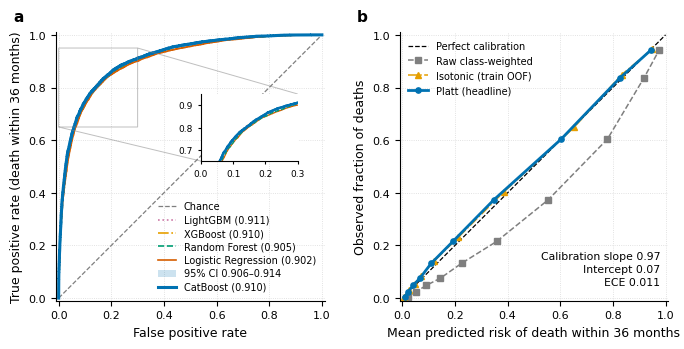

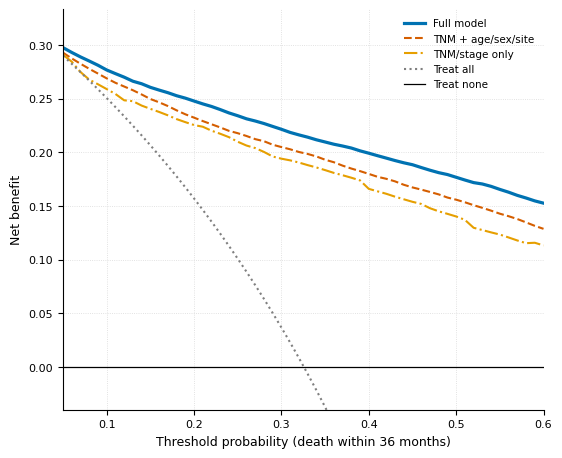

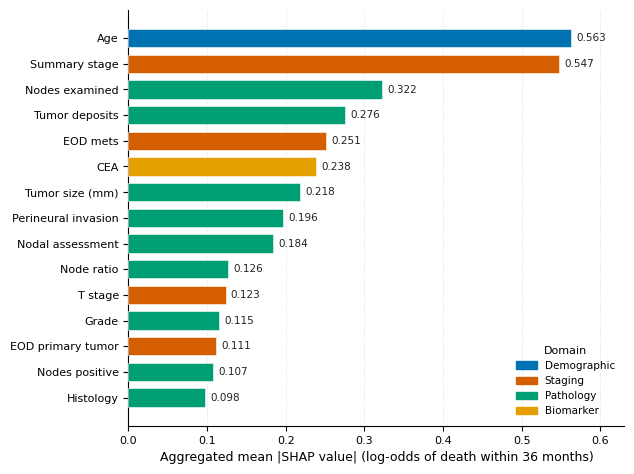

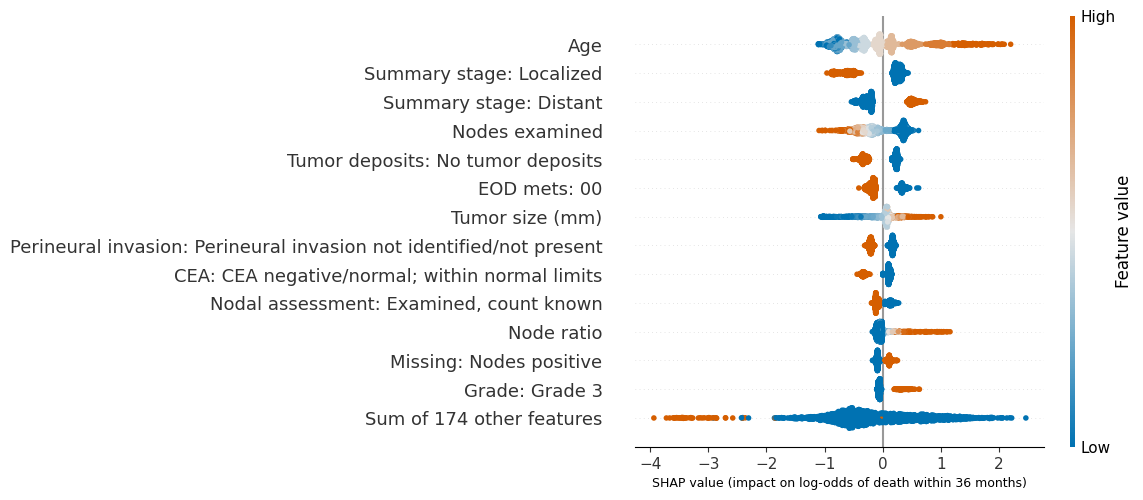

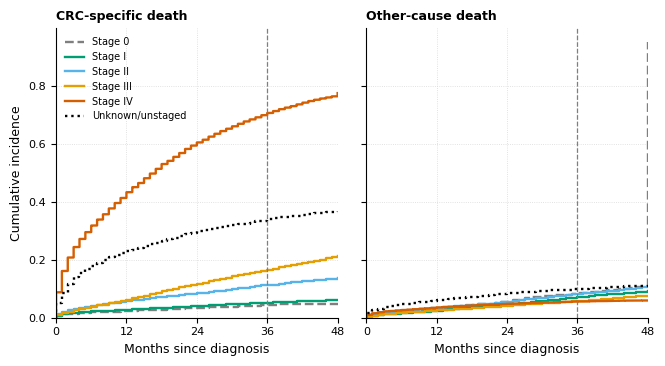

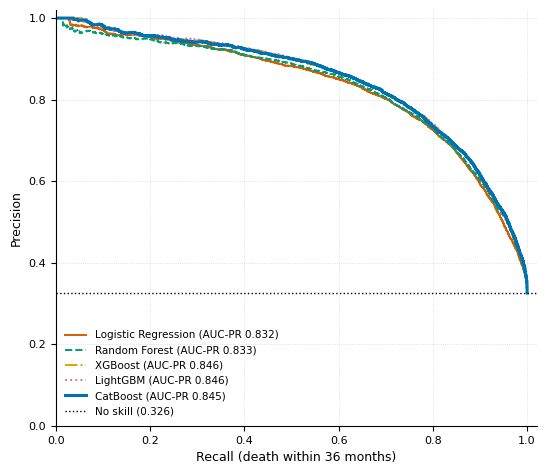

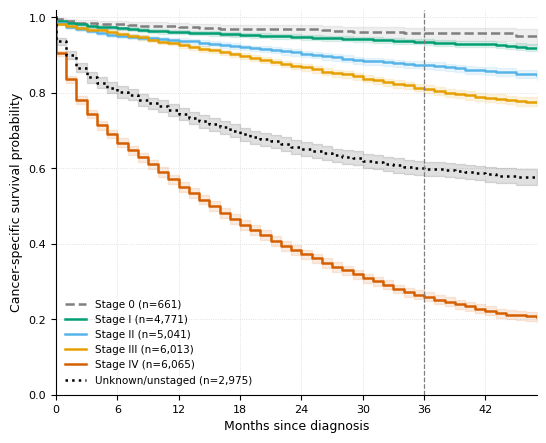

In [16]:
# plotting style and colours (colour-blind safe)
OI = dict(blue="#0072B2", verm="#D55E00", green="#009E73", orange="#E69F00", purple="#CC79A7", sky="#56B4E9", grey="#7F7F7F", black="#000000")
plt.rcParams.update({"font.size": 8, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#D9D9D9", "grid.linestyle": ":",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False, "savefig.facecolor": "white"})

other_models = [m for m in MODEL_NAMES if m != BEST]
model_color = {BEST: OI["blue"], **dict(zip(other_models, [OI["verm"], OI["green"], OI["orange"], OI["purple"]]))}
model_style = {BEST: "-", **dict(zip(other_models, ["-", "--", "-.", ":"]))}
auc_by_model = {m: roc_auc_score(yd_test, 1 - p_surv[m]) for m in MODEL_NAMES}

def save_figure(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=600, bbox_inches="tight", pad_inches=0.03)
    plt.show()
    plt.close(fig)

# ---- Figure 2: (a) ROC curves, (b) calibration
fig, (ax_roc, ax_cal) = plt.subplots(1, 2, figsize=(6.69, 3.6))
fig.subplots_adjust(left=0.08, right=0.995, top=0.94, bottom=0.14, wspace=0.28)

ax_roc.plot([0, 1], [0, 1], ls="--", color=OI["grey"], lw=0.9, label="Chance")
for m in sorted(other_models, key=lambda m: -auc_by_model[m]):
    fpr, tpr, _ = roc_curve(yd_test, 1 - p_surv[m])
    ax_roc.plot(fpr, tpr, color=model_color[m], ls=model_style[m], lw=1.2, label=f"{m} ({auc_by_model[m]:.3f})")
ax_roc.fill_between(FPR_GRID, tpr_lo, tpr_hi, color=OI["blue"], alpha=0.20, lw=0, label=f"95% CI {auc_lo:.3f}\u2013{auc_hi:.3f}")
fpr, tpr, _ = roc_curve(yd_test, pd_head)
ax_roc.plot(fpr, tpr, color=OI["blue"], lw=2.2, label=f"{BEST} ({auc_by_model[BEST]:.3f})")
ax_roc.legend(loc="lower right", handlelength=1.8, labelspacing=0.35, fontsize=7)
ax_roc.set_xlabel("False positive rate"); ax_roc.set_ylabel("True positive rate (death within 36 months)")
ax_roc.set_xlim(-0.01, 1.01); ax_roc.set_ylim(-0.01, 1.01); ax_roc.set_aspect("equal", adjustable="box")
inset = ax_roc.inset_axes([0.54, 0.52, 0.36, 0.25]); inset.grid(False)
for m in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(yd_test, 1 - p_surv[m])
    inset.plot(fpr, tpr, color=model_color[m], ls=model_style[m], lw=1.8 if m == BEST else 0.9)
inset.set_xlim(0, 0.3); inset.set_ylim(0.65, 0.95); inset.tick_params(labelsize=6.5, length=2.5)
ax_roc.indicate_inset_zoom(inset, edgecolor=OI["grey"], lw=0.7)

cal_style = {"Raw class-weighted": (OI["grey"], "s", "--", 1.1), "Isotonic (train OOF)": (OI["orange"], "^", "-.", 1.1), "Platt (headline)": (OI["blue"], "o", "-", 2.0)}
ax_cal.plot([0, 1], [0, 1], ls="--", color="black", lw=0.9, label="Perfect calibration")
for name, p in cal_variants.items():
    color, marker, linestyle, width = cal_style[name]
    observed, predicted = calibration_curve(yd_test, p, n_bins=10, strategy="quantile")
    ax_cal.plot(predicted, observed, marker=marker, ms=3.8, ls=linestyle, lw=width, color=color, label=name)
ax_cal.set_xlim(-0.01, 1.01); ax_cal.set_ylim(-0.01, 1.01); ax_cal.set_aspect("equal", adjustable="box")
ax_cal.set_xlabel("Mean predicted risk of death within 36 months"); ax_cal.set_ylabel("Observed fraction of deaths")
ax_cal.legend(loc="upper left", fontsize=7)
ax_cal.text(0.97, 0.05, f"Calibration slope {cal_slope:.2f}\nIntercept {cal_intercept:.2f}\nECE {ece_head:.3f}", transform=ax_cal.transAxes,
            ha="right", va="bottom", fontsize=7.8, linespacing=1.4)
for ax, letter in [(ax_roc, "a"), (ax_cal, "b")]:
    ax.text(-0.16, 1.03, letter, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="left")
save_figure(fig, "Fig2_ROC_calibration")

# ---- Figure 3: decision curve analysis
fig, ax = plt.subplots(figsize=(6.2, 5.2))
curves = [("Full model", pd_head, OI["blue"], "-", 2.3), ("TNM + age/sex/site", pd_model2, OI["verm"], "--", 1.5), ("TNM/stage only", pd_model1, OI["orange"], "-.", 1.5)]
top = 0
for label, p, color, linestyle, width in curves:
    nb = net_benefit(yd_test, p, DCA_GRID)
    top = max(top, nb.max())
    ax.plot(DCA_GRID, nb, color=color, ls=linestyle, lw=width, label=label)
ax.plot(DCA_GRID, net_benefit_treat_all(yd_test, DCA_GRID), ls=":", color=OI["grey"], lw=1.5, label="Treat all")
ax.axhline(0, color="black", lw=0.9, label="Treat none")
ax.set_ylim(-0.04, top * 1.12); ax.set_xlim(DCA_GRID.min(), DCA_GRID.max())
ax.set_xlabel("Threshold probability (death within 36 months)"); ax.set_ylabel("Net benefit")
ax.legend(loc="upper right")
save_figure(fig, "Fig3_dca")

# ---- Figure 4: aggregated SHAP importance (top 15)
domain_color = {"Demographic": OI["blue"], "Staging": OI["verm"], "Pathology": OI["green"], "Biomarker": OI["orange"],
                "Anatomic": OI["purple"], "Diagnostic": OI["sky"], "Other": OI["grey"]}
top15 = table_s5b.head(15).iloc[::-1].reset_index(drop=True)
values = top15["Aggregated mean |SHAP|"].values
domains = [DOMAIN.get(o, "Other") for o in top15["Original feature"]]
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.barh(top15["Clinical feature"], values, color=[domain_color[d] for d in domains], height=0.72, edgecolor="white", lw=0.4, zorder=3)
for y_pos, v in enumerate(values):
    ax.text(v + values.max() * 0.012, y_pos, f"{v:.3f}", va="center", fontsize=7.5, color="#222")
ax.set_xlim(0, values.max() * 1.12)
ax.set_xlabel("Aggregated mean |SHAP value| (log-odds of death within 36 months)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=domain_color[d], label=d) for d in domain_color if d in domains], title="Domain", loc="lower right", title_fontsize=8)
save_figure(fig, "Fig4_shap_aggregated")

# ---- Figure 5: SHAP beeswarm
from matplotlib.colors import LinearSegmentedColormap
explanation = shap.Explanation(values=shap_death, base_values=np.full(len(shap_death), -base_value), data=X_shap,
                               feature_names=[readable_name(n) for n in encoded_names])
plt.rcParams["axes.grid"] = False
fig = plt.figure(figsize=(6.6, 5.6))
shap.plots.beeswarm(explanation, max_display=14, show=False, color=LinearSegmentedColormap.from_list("div", [OI["blue"], "#E6E6E6", OI["verm"]]), plot_size=None)
fig = plt.gcf(); fig.set_size_inches(6.6, 5.6)
fig.axes[0].set_xlabel("SHAP value (impact on log-odds of death within 36 months)", fontsize=9)
save_figure(fig, "Fig5_shap_beeswarm")
plt.rcParams["axes.grid"] = True

# ---- Figure 6: cumulative incidence by stage
STAGE_ORDER = ["Stage 0", "Stage I", "Stage II", "Stage III", "Stage IV", "Unknown/unstaged"]
STAGE_COLOR = {"Stage 0": OI["grey"], "Stage I": OI["green"], "Stage II": OI["sky"], "Stage III": OI["orange"], "Stage IV": OI["verm"], "Unknown/unstaged": OI["black"]}
STAGE_STYLE = {"Unknown/unstaged": ":", "Stage 0": "--"}
fig, axes = plt.subplots(1, 2, figsize=(6.69, 3.7), sharey=True)
for stage in [s for s in STAGE_ORDER if s in cif_curves]:
    for ax, curve, i in zip(axes, cif_curves[stage], [0, 1]):
        ax.step(curve.index, curve.iloc[:, 0], where="post", color=STAGE_COLOR[stage], ls=STAGE_STYLE.get(stage, "-"), lw=1.7, label=stage if i == 0 else None)
for ax, title in zip(axes, ["CRC-specific death", "Other-cause death"]):
    ax.axvline(HORIZON, ls="--", color=OI["grey"], lw=0.9)
    ax.set_xlim(0, CIF_MONTHS); ax.set_xticks(np.arange(0, CIF_MONTHS + 1, 12)); ax.set_xlabel("Months since diagnosis")
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Cumulative incidence"); axes[0].set_ylim(bottom=0); axes[0].legend(loc="upper left", fontsize=7)
fig.tight_layout(w_pad=1.5)
save_figure(fig, "Fig6_cif_by_stage")

# ---- Figure S1: precision-recall curves of all models
fig, ax = plt.subplots(figsize=(6.2, 5.4))
for m in MODEL_NAMES:
    precision, recall, _ = precision_recall_curve(yd_test, 1 - p_surv[m])
    ax.plot(recall, precision, color=model_color[m], ls=model_style[m], lw=2.2 if m == BEST else 1.4,
            label=f"{m} (AUC-PR {average_precision_score(yd_test, 1 - p_surv[m]):.3f})")
ax.axhline(yd_test.mean(), ls=":", color="black", lw=1, label=f"No skill ({yd_test.mean():.3f})")
ax.set_xlabel("Recall (death within 36 months)"); ax.set_ylabel("Precision")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.legend(loc="lower left")
save_figure(fig, "SF1_pr_all_models")

# ---- Figure S2: Kaplan-Meier by stage, 2020 full cohort
km_data = feat_full[full_test]
fig, ax = plt.subplots(figsize=(6.2, 5.0))
max_month = float(km_data["survival_months"].max())
for stage in STAGE_ORDER:
    g = km_data[km_data["stage_group_clean"] == stage]
    if len(g) < MIN_SUBGROUP: continue
    km = KaplanMeierFitter().fit(g["survival_months"].clip(lower=0.01), g["death_event_crc"], label=f"{stage} (n={len(g):,})")
    km.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.12, color=STAGE_COLOR[stage], ls=STAGE_STYLE.get(stage, "-"), lw=1.8)
if max_month >= HORIZON: ax.axvline(HORIZON, ls="--", color=OI["grey"], lw=0.9)
ax.set_xlim(0, max_month); ax.set_ylim(0, 1.02); ax.set_xticks(np.arange(0, max_month + 1, 6))
ax.set_xlabel("Months since diagnosis"); ax.set_ylabel("Cancer-specific survival probability"); ax.legend(loc="lower left")
save_figure(fig, "SF2_kaplan_meier_by_stage")

## 17. Reproducibility check

Confirms that refitting the selected model reproduces the test AUC-ROC and that the saved calibrator reproduces the headline result.

In [17]:
# refitting the selected model must give the same test AUC, and the saved calibrator must reproduce the headline AUC
refit = make_pipeline(X_train, BEST, best_params[BEST]).fit(X_train, y_train)
auc_refit = roc_auc_score(yd_test, 1 - refit.predict_proba(X_test)[:, 1])
auc_first = roc_auc_score(yd_test, 1 - p_raw[BEST])
assert abs(auc_refit - auc_first) < 1e-9, "refit gives a different AUC"
assert abs(roc_auc_score(yd_test, 1 - predict_survival(best_pipeline, best_platt, X_test)) - headline_auc) < 1e-12
print(f"Reproducibility checks passed. Headline AUC-ROC {headline_auc:.4f} (95% CI {auc_lo:.3f}-{auc_hi:.3f}), AUC-PR {average_precision_score(yd_test, pd_head):.4f}")

Reproducibility checks passed. Headline AUC-ROC 0.9104 (95% CI 0.906-0.914), AUC-PR 0.8454
